In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Medical_appointment_data.csv")

print("Dataset Shape:", df.shape)
print(df.head())

FileNotFoundError: [Errno 2] No such file or directory: 'Medical_appointment_data.csv'

In [2]:
import os

print(os.getcwd())
print(os.listdir())


c:\Users\sadhu\Documents\Medical-Appointment-No-Show\notebooks
['business cases', 'medical_appointment_analysis.ipynb', 'Medical_Appointment_Demand_Forecasting.ipynb']


In [3]:
import os

parent_path = os.path.dirname(os.getcwd())

print(os.listdir(parent_path))

['.git', '.gitignore', 'app.py', 'data', 'medical_no_show_features.pkl', 'medical_no_show_model.pkl', 'medical_no_show_preprocessor.pkl', 'notebooks', 'README.md', 'requirements.txt']


In [4]:
data_path = os.path.join(parent_path, "data")

print(os.listdir(data_path))

['Medical_appointment_data.csv']


In [5]:
df = pd.read_csv(os.path.join(data_path, "Medical_appointment_data.csv"))

print("Dataset Shape:", df.shape)
print(df.head())


Dataset Shape: (109593, 26)
        specialty  appointment_time gender no_show    disability  \
0   psychotherapy                17      F     yes  intellectual   
1             NaN                 7      M      no  intellectual   
2  speech therapy                16      M      no  intellectual   
3  speech therapy                14      M     yes  intellectual   
4   physiotherapy                 8      M      no         motor   

              place appointment_shift   age  under_12_years_old  \
0  Lake Marvinville         afternoon   9.0                   1   
1           ITAPEMA           morning  11.0                   1   
2            ITAJAÍ         afternoon   8.0                   1   
3         Sarahside         afternoon   9.0                   1   
4            ITAJAÍ           morning   NaN                   0   

   over_60_years_old  ...  storm_day_before  rain_intensity  heat_intensity  \
0                  0  ...                 1         no_rain            warm   
1 

In [6]:
print(df['appointment_date_continuous'].dtype)

print(df['appointment_date_continuous'].head())

print("Unique dates:",
      df['appointment_date_continuous'].nunique())

str
0    2020-01-01
1    2020-01-01
2    2020-01-01
3    2020-01-01
4    2020-01-01
Name: appointment_date_continuous, dtype: str
Unique dates: 498


In [7]:
df['appointment_date_continuous'] = pd.to_datetime(
    df['appointment_date_continuous']
)

print(df['appointment_date_continuous'].dtype)

datetime64[us]


In [8]:
print("Start Date:", df['appointment_date_continuous'].min())

print("End Date:", df['appointment_date_continuous'].max())

print("Total Unique Dates:",
      df['appointment_date_continuous'].nunique())

Start Date: 2020-01-01 00:00:00
End Date: 2021-05-12 00:00:00
Total Unique Dates: 498


In [9]:
daily_demand = (
    df.groupby('appointment_date_continuous')
    .size()
    .reset_index(name='appointment_count')
)

print(daily_demand.head(10))

  appointment_date_continuous  appointment_count
0                  2020-01-01                 25
1                  2020-01-02                 33
2                  2020-01-03                 18
3                  2020-01-04                 16
4                  2020-01-05                 15
5                  2020-01-06                  2
6                  2020-01-07                  7
7                  2020-01-08                 32
8                  2020-01-09                 17
9                  2020-01-10                 38


In [10]:
print("Average Daily Demand:",
      daily_demand['appointment_count'].mean())

print("Maximum Daily Demand:",
      daily_demand['appointment_count'].max())

print("Minimum Daily Demand:",
      daily_demand['appointment_count'].min())

print("Total Appointments:",
      daily_demand['appointment_count'].sum())

Average Daily Demand: 220.06626506024097
Maximum Daily Demand: 1512
Minimum Daily Demand: 1
Total Appointments: 109593


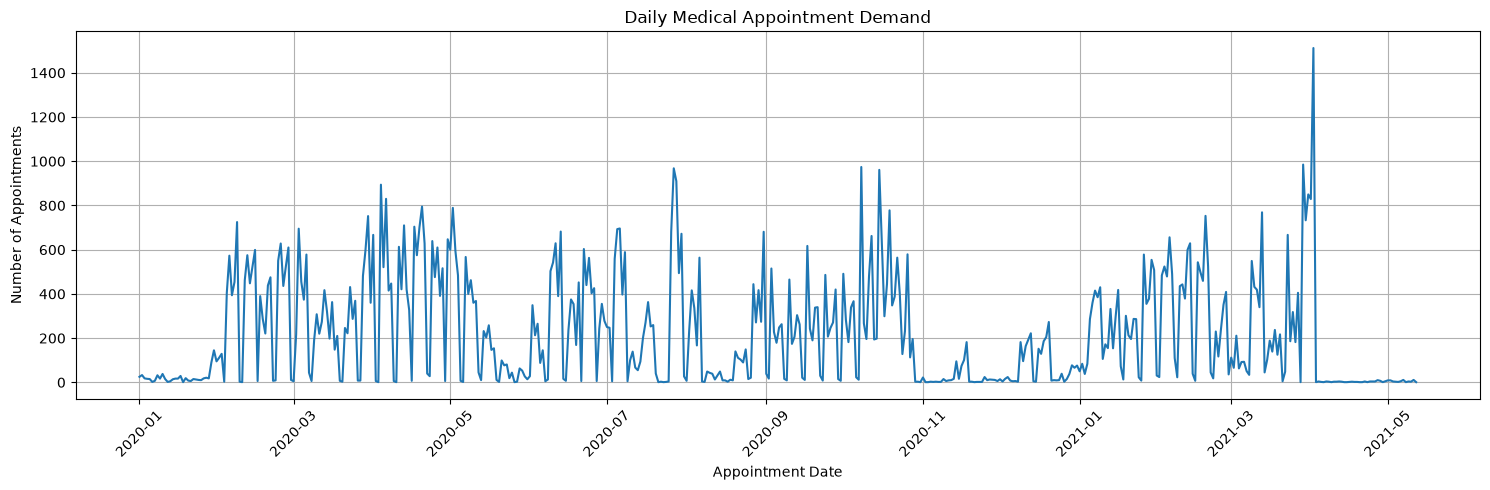

In [11]:
plt.figure(figsize=(15, 5))

plt.plot(
    daily_demand['appointment_date_continuous'],
    daily_demand['appointment_count']
)

plt.title("Daily Medical Appointment Demand")
plt.xlabel("Appointment Date")
plt.ylabel("Number of Appointments")

plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

In [12]:
print(daily_demand['appointment_count'].describe())

count     498.000000
mean      220.066265
std       245.803633
min         1.000000
25%        10.000000
50%       126.500000
75%       393.250000
max      1512.000000
Name: appointment_count, dtype: float64


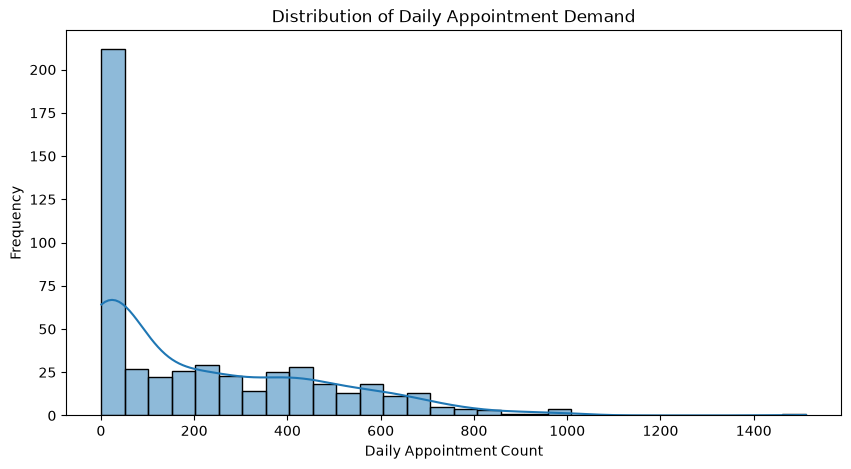

In [13]:
plt.figure(figsize=(10, 5))

sns.histplot(
    daily_demand['appointment_count'],
    bins=30,
    kde=True
)

plt.title("Distribution of Daily Appointment Demand")
plt.xlabel("Daily Appointment Count")
plt.ylabel("Frequency")

plt.show()

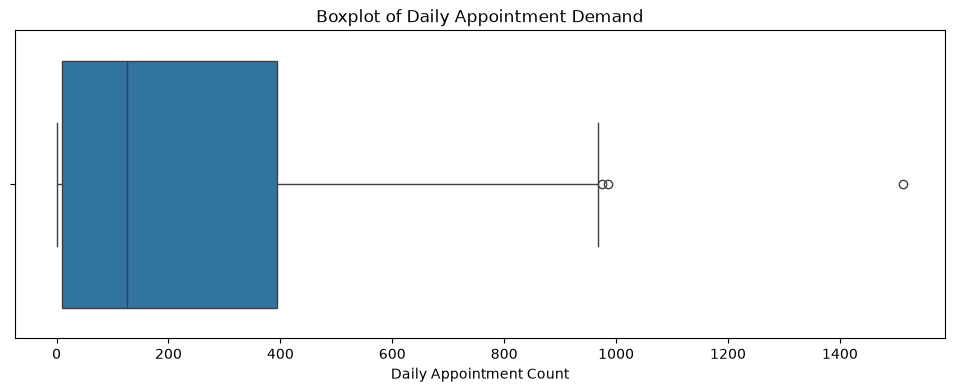

In [14]:
plt.figure(figsize=(12, 4))

sns.boxplot(x=daily_demand['appointment_count'])

plt.title("Boxplot of Daily Appointment Demand")
plt.xlabel("Daily Appointment Count")

plt.show()

In [15]:
Q1 = daily_demand['appointment_count'].quantile(0.25)
Q3 = daily_demand['appointment_count'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

outliers = daily_demand[
    (daily_demand['appointment_count'] < lower_bound) |
    (daily_demand['appointment_count'] > upper_bound)
]

print("\nNumber of Outliers:", len(outliers))
print(outliers)

Q1: 10.0
Q3: 393.25
IQR: 383.25
Lower Bound: -564.875
Upper Bound: 968.125

Number of Outliers: 3
    appointment_date_continuous  appointment_count
281                  2020-10-08                974
453                  2021-03-29                985
457                  2021-04-02               1512


In [16]:
outlier_dates = outliers['appointment_date_continuous']

outlier_data = df[
    df['appointment_date_continuous'].isin(outlier_dates)
]

print(
    outlier_data.groupby(
        ['appointment_date_continuous', 'specialty'],
        dropna=False
    ).size().reset_index(name='appointment_count')
)

   appointment_date_continuous             specialty  appointment_count
0                   2020-10-08                assist                  6
1                   2020-10-08                   enf                 11
2                   2020-10-08  occupational therapy                107
3                   2020-10-08              pedagogo                 26
4                   2020-10-08         physiotherapy                191
5                   2020-10-08         psychotherapy                256
6                   2020-10-08     sem especialidade                  3
7                   2020-10-08        speech therapy                201
8                   2020-10-08                   NaN                173
9                   2021-03-29                assist                  5
10                  2021-03-29                   enf                 11
11                  2021-03-29  occupational therapy                 97
12                  2021-03-29              pedagogo            

In [17]:
daily_demand['day_of_week'] = (
    daily_demand['appointment_date_continuous'].dt.day_name()
)

print(daily_demand.head())

  appointment_date_continuous  appointment_count day_of_week
0                  2020-01-01                 25   Wednesday
1                  2020-01-02                 33    Thursday
2                  2020-01-03                 18      Friday
3                  2020-01-04                 16    Saturday
4                  2020-01-05                 15      Sunday


In [18]:
weekday_demand = (
    daily_demand.groupby('day_of_week')['appointment_count']
    .mean()
    .reindex([
        'Monday',
        'Tuesday',
        'Wednesday',
        'Thursday',
        'Friday',
        'Saturday',
        'Sunday'
    ])
)

print(weekday_demand)

day_of_week
Monday       228.746479
Tuesday      218.859155
Wednesday    199.097222
Thursday     258.873239
Friday       239.887324
Saturday     239.014085
Sunday       156.281690
Name: appointment_count, dtype: float64


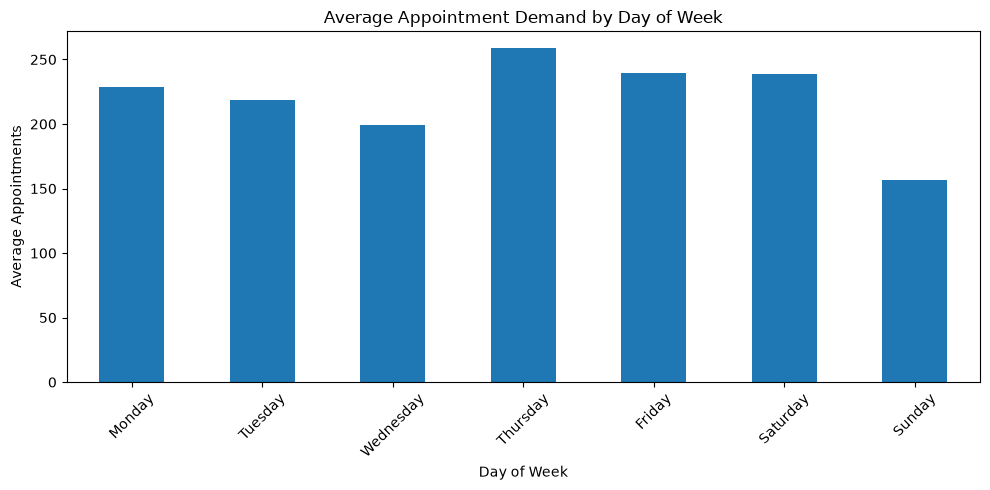

In [19]:
plt.figure(figsize=(10, 5))

weekday_demand.plot(kind='bar')

plt.title("Average Appointment Demand by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Appointments")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
daily_demand['month'] = (
    daily_demand['appointment_date_continuous'].dt.month_name()
)

daily_demand['year'] = (
    daily_demand['appointment_date_continuous'].dt.year
)

print(daily_demand.head())

  appointment_date_continuous  appointment_count day_of_week    month  year
0                  2020-01-01                 25   Wednesday  January  2020
1                  2020-01-02                 33    Thursday  January  2020
2                  2020-01-03                 18      Friday  January  2020
3                  2020-01-04                 16    Saturday  January  2020
4                  2020-01-05                 15      Sunday  January  2020


In [21]:
monthly_demand = (
    daily_demand.groupby('month')['appointment_count']
    .mean()
)

print(monthly_demand)

month
April        257.750000
August       152.000000
December      72.290323
February     342.859649
January      134.532258
July         291.709677
June         292.833333
March        281.629032
May          145.093023
November      21.633333
October      346.419355
September    212.500000
Name: appointment_count, dtype: float64


In [22]:
monthly_year_demand = (
    daily_demand.groupby(['year', 'month'])['appointment_count']
    .mean()
    .reset_index()
)

print(monthly_year_demand)

    year      month  appointment_count
0   2020      April         434.733333
1   2020     August         152.000000
2   2020   December          72.290323
3   2020   February         344.758621
4   2020    January          24.903226
5   2020       July         291.709677
6   2020       June         292.833333
7   2020      March         283.741935
8   2020        May         199.225806
9   2020   November          21.633333
10  2020    October         346.419355
11  2020  September         212.500000
12  2021      April          80.766667
13  2021   February         340.892857
14  2021    January         244.161290
15  2021      March         279.516129
16  2021        May           5.250000


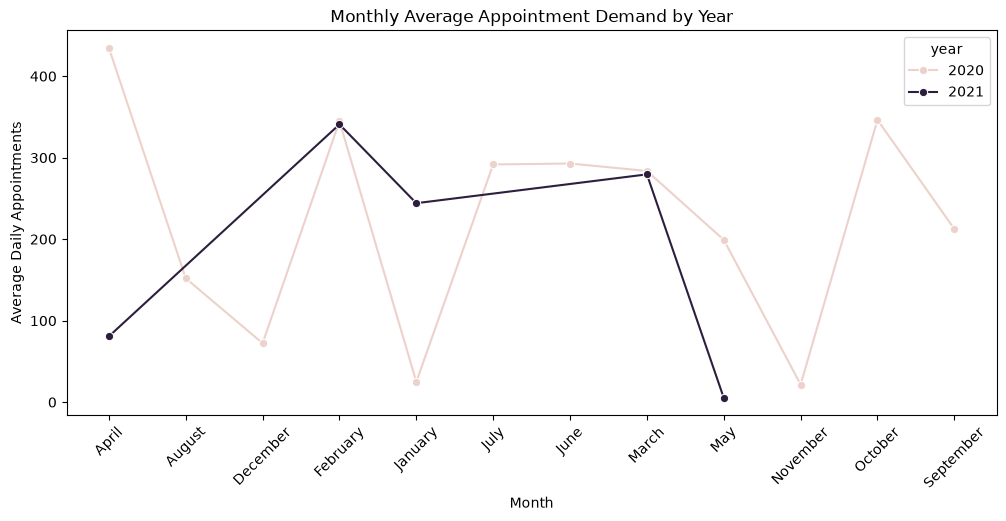

In [23]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_year_demand,
    x='month',
    y='appointment_count',
    hue='year',
    marker='o'
)

plt.title("Monthly Average Appointment Demand by Year")
plt.xlabel("Month")
plt.ylabel("Average Daily Appointments")
plt.xticks(rotation=45)
plt.show()

In [24]:
specialty_demand = (
    df.groupby('specialty', dropna=False)
    .size()
    .reset_index(name='total_appointments')
    .sort_values(by='total_appointments', ascending=False)
)

print(specialty_demand)

              specialty  total_appointments
5         psychotherapy               28645
7        speech therapy               22322
4         physiotherapy               21004
8                   NaN               20127
2  occupational therapy               11319
3              pedagogo                3536
1                   enf                1681
0                assist                 635
6     sem especialidade                 324


In [25]:
specialty_daily_demand = (
    df.groupby(
        ['appointment_date_continuous', 'specialty'],
        dropna=False
    )
    .size()
    .reset_index(name='appointment_count')
)

print(specialty_daily_demand.head(10))

  appointment_date_continuous             specialty  appointment_count
0                  2020-01-01                assist                  1
1                  2020-01-01  occupational therapy                  3
2                  2020-01-01         physiotherapy                  6
3                  2020-01-01         psychotherapy                  7
4                  2020-01-01        speech therapy                  6
5                  2020-01-01                   NaN                  2
6                  2020-01-02  occupational therapy                  4
7                  2020-01-02              pedagogo                  3
8                  2020-01-02         physiotherapy                  7
9                  2020-01-02         psychotherapy                 12


In [26]:
print("Dataset Shape:", specialty_daily_demand.shape)

print(
    "Start Date:",
    specialty_daily_demand['appointment_date_continuous'].min()
)

print(
    "End Date:",
    specialty_daily_demand['appointment_date_continuous'].max()
)

print(
    "Number of Specialties:",
    specialty_daily_demand['specialty'].nunique(dropna=False)
)

Dataset Shape: (3256, 3)
Start Date: 2020-01-01 00:00:00
End Date: 2021-05-12 00:00:00
Number of Specialties: 9


In [27]:
all_dates = pd.date_range(
    start=df['appointment_date_continuous'].min(),
    end=df['appointment_date_continuous'].max(),
    freq='D'
)

specialties = df['specialty'].dropna().unique().tolist()
specialties.append('Unknown')

specialty_daily_demand['specialty'] = (
    specialty_daily_demand['specialty'].fillna('Unknown')
)

full_index = pd.MultiIndex.from_product(
    [all_dates, specialties],
    names=['appointment_date_continuous', 'specialty']
)

specialty_daily_demand = (
    specialty_daily_demand
    .set_index(['appointment_date_continuous', 'specialty'])
    .reindex(full_index, fill_value=0)
    .reset_index()
)

print("New Dataset Shape:", specialty_daily_demand.shape)
print(specialty_daily_demand.head(15))

New Dataset Shape: (4482, 3)
   appointment_date_continuous             specialty  appointment_count
0                   2020-01-01         psychotherapy                  7
1                   2020-01-01        speech therapy                  6
2                   2020-01-01         physiotherapy                  6
3                   2020-01-01  occupational therapy                  3
4                   2020-01-01                assist                  1
5                   2020-01-01              pedagogo                  0
6                   2020-01-01                   enf                  0
7                   2020-01-01     sem especialidade                  0
8                   2020-01-01               Unknown                  2
9                   2020-01-02         psychotherapy                 12
10                  2020-01-02        speech therapy                  4
11                  2020-01-02         physiotherapy                  7
12                  2020-01-02  occ

In [28]:
print("Total Appointments:", specialty_daily_demand['appointment_count'].sum())

print("Original Appointments:", len(df))

print("\nRecords per Specialty:")
print(specialty_daily_demand.groupby('specialty').size())

print("\nZero-Demand Records:")
print((specialty_daily_demand['appointment_count'] == 0).sum())

Total Appointments: 109593
Original Appointments: 109593

Records per Specialty:
specialty
Unknown                 498
assist                  498
enf                     498
occupational therapy    498
pedagogo                498
physiotherapy           498
psychotherapy           498
sem especialidade       498
speech therapy          498
dtype: int64

Zero-Demand Records:
1226


In [29]:
overall_demand = daily_demand[
    ['appointment_date_continuous', 'appointment_count']
].copy()

overall_demand = overall_demand.sort_values(
    'appointment_date_continuous'
).reset_index(drop=True)

print(overall_demand.head())
print("\nDataset Shape:", overall_demand.shape)
print("\nMissing Values:")
print(overall_demand.isnull().sum())

  appointment_date_continuous  appointment_count
0                  2020-01-01                 25
1                  2020-01-02                 33
2                  2020-01-03                 18
3                  2020-01-04                 16
4                  2020-01-05                 15

Dataset Shape: (498, 2)

Missing Values:
appointment_date_continuous    0
appointment_count              0
dtype: int64


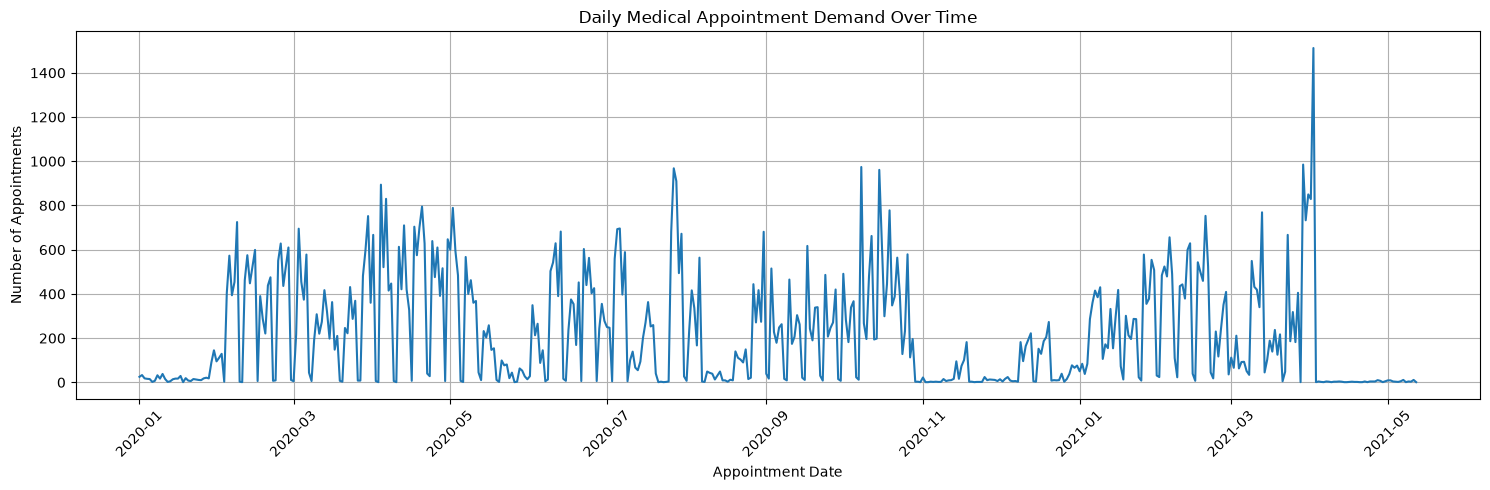

In [30]:
plt.figure(figsize=(15, 5))

plt.plot(
    overall_demand['appointment_date_continuous'],
    overall_demand['appointment_count']
)

plt.title("Daily Medical Appointment Demand Over Time")
plt.xlabel("Appointment Date")
plt.ylabel("Number of Appointments")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [31]:
split_index = int(len(overall_demand) * 0.8)

train_data = overall_demand.iloc[:split_index].copy()
test_data = overall_demand.iloc[split_index:].copy()

print("Training Shape:", train_data.shape)
print("Testing Shape:", test_data.shape)

print("\nTraining Period:")
print(train_data['appointment_date_continuous'].min())
print(train_data['appointment_date_continuous'].max())

print("\nTesting Period:")
print(test_data['appointment_date_continuous'].min())
print(test_data['appointment_date_continuous'].max())

Training Shape: (398, 2)
Testing Shape: (100, 2)

Training Period:
2020-01-01 00:00:00
2021-02-01 00:00:00

Testing Period:
2021-02-02 00:00:00
2021-05-12 00:00:00


In [32]:
last_value = train_data['appointment_count'].iloc[-1]

naive_predictions = [last_value] * len(test_data)

print("Last Training Day Demand:", last_value)
print("First 10 Predictions:", naive_predictions[:10])

Last Training Day Demand: 24
First 10 Predictions: [np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24), np.int64(24)]


In [33]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(
    test_data['appointment_count'],
    naive_predictions
)

rmse = np.sqrt(
    mean_squared_error(
        test_data['appointment_count'],
        naive_predictions
    )
)

mape = np.mean(
    np.abs(
        (test_data['appointment_count'] - naive_predictions)
        / test_data['appointment_count']
    )
) * 100

print("Naive Model Evaluation")
print("MAE:", mae)
print("RMSE:", rmse)
print("MAPE:", mape)

Naive Model Evaluation
MAE: 200.34
RMSE: 337.8505586794256
MAPE: 494.89599514553373


In [34]:
from sklearn.metrics import r2_score

r2 = r2_score(
    test_data['appointment_count'],
    naive_predictions
)

print("R2 Score:", r2)

R2 Score: -0.4134235520469254


In [35]:
rolling_mean = (
    train_data['appointment_count']
    .rolling(window=7)
    .mean()
)

moving_average_value = rolling_mean.iloc[-1]

moving_average_predictions = [
    moving_average_value
] * len(test_data)

print("Last 7-Day Average:", moving_average_value)
print("First 10 Predictions:", moving_average_predictions[:10])

Last 7-Day Average: 346.85714285714283
First 10 Predictions: [np.float64(346.85714285714283), np.float64(346.85714285714283), np.float64(346.85714285714283), np.float64(346.85714285714283), np.float64(346.85714285714283), np.float64(346.85714285714283), np.float64(346.85714285714283), np.float64(346.85714285714283), np.float64(346.85714285714283), np.float64(346.85714285714283)]


In [36]:
ma_mae = mean_absolute_error(
    test_data['appointment_count'],
    moving_average_predictions
)

ma_rmse = np.sqrt(
    mean_squared_error(
        test_data['appointment_count'],
        moving_average_predictions
    )
)

ma_mape = np.mean(
    np.abs(
        (test_data['appointment_count'] - moving_average_predictions)
        / test_data['appointment_count']
    )
) * 100

ma_r2 = r2_score(
    test_data['appointment_count'],
    moving_average_predictions
)

print("Moving Average Model Evaluation")
print("MAE:", ma_mae)
print("RMSE:", ma_rmse)
print("MAPE:", ma_mape)
print("R2:", ma_r2)

Moving Average Model Evaluation
MAE: 282.0371428571427
RMSE: 316.85141692623574
MAPE: 7183.305631293311
R2: -0.24318095431537


In [37]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

In [39]:
ses_model = SimpleExpSmoothing(
    train_data['appointment_count'].to_numpy(),
    initialization_method='estimated'
).fit(
    optimized=True
)

ses_predictions = ses_model.forecast(
    len(test_data)
)

print("First 10 Predictions:")
print(ses_predictions[:10])

First 10 Predictions:
[245.68084663 245.68084663 245.68084663 245.68084663 245.68084663
 245.68084663 245.68084663 245.68084663 245.68084663 245.68084663]


In [40]:
ses_mae = mean_absolute_error(
    test_data['appointment_count'],
    ses_predictions
)

ses_rmse = np.sqrt(
    mean_squared_error(
        test_data['appointment_count'],
        ses_predictions
    )
)

actual = test_data['appointment_count'].to_numpy()

non_zero_mask = actual != 0

ses_mape = np.mean(
    np.abs(
        (actual[non_zero_mask] - ses_predictions[non_zero_mask])
        / actual[non_zero_mask]
    )
) * 100

ses_r2 = r2_score(
    actual,
    ses_predictions
)

print("Simple Exponential Smoothing Evaluation")
print("MAE:", ses_mae)
print("RMSE:", ses_rmse)
print("MAPE:", ses_mape)
print("R2:", ses_r2)

Simple Exponential Smoothing Evaluation
MAE: 240.85233865343267
RMSE: 286.8350556860257
MAPE: 5076.150498096611
R2: -0.01879662219131717


In [41]:
from statsmodels.tsa.holtwinters import Holt

holt_model = Holt(
    train_data['appointment_count'].to_numpy(),
    initialization_method='estimated'
).fit(
    optimized=True
)

holt_predictions = holt_model.forecast(
    len(test_data)
)

print("First 10 Predictions:")
print(holt_predictions[:10])

First 10 Predictions:
[248.46717701 249.04321624 249.61925546 250.19529469 250.77133391
 251.34737314 251.92341236 252.49945158 253.07549081 253.65153003]


In [42]:
holt_mae = mean_absolute_error(
    test_data['appointment_count'],
    holt_predictions
)

holt_rmse = np.sqrt(
    mean_squared_error(
        test_data['appointment_count'],
        holt_predictions
    )
)

actual = test_data['appointment_count'].to_numpy()
non_zero_mask = actual != 0

holt_mape = np.mean(
    np.abs(
        (actual[non_zero_mask] - holt_predictions[non_zero_mask])
        / actual[non_zero_mask]
    )
) * 100

holt_r2 = r2_score(
    actual,
    holt_predictions
)

print("Holt's Linear Trend Evaluation")
print("MAE:", holt_mae)
print("RMSE:", holt_rmse)
print("MAPE:", holt_mape)
print("R2:", holt_r2)

Holt's Linear Trend Evaluation
MAE: 261.18353932458865
RMSE: 300.38501670500034
MAPE: 6031.661929001905
R2: -0.11732514665268745


In [43]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

hw_model = ExponentialSmoothing(
    train_data['appointment_count'].to_numpy(),
    trend='add',
    seasonal='add',
    seasonal_periods=7,
    initialization_method='estimated'
).fit(optimized=True)

hw_predictions = hw_model.forecast(len(test_data))

print("First 10 Predictions:")
print(hw_predictions[:10])

First 10 Predictions:
[450.22958254 344.5457166  322.25822012 420.56941758 404.13616459
  72.66368304 144.25585283 455.29279955 349.6089336  327.32143713]


In [44]:
hw_mae = mean_absolute_error(
    test_data['appointment_count'],
    hw_predictions
)

hw_rmse = np.sqrt(
    mean_squared_error(
        test_data['appointment_count'],
        hw_predictions
    )
)

actual = test_data['appointment_count'].to_numpy()
non_zero_mask = actual != 0

hw_mape = np.mean(
    np.abs(
        (actual[non_zero_mask] - hw_predictions[non_zero_mask])
        / actual[non_zero_mask]
    )
) * 100

hw_r2 = r2_score(
    actual,
    hw_predictions
)

print("Holt-Winters Evaluation")
print("MAE:", hw_mae)
print("RMSE:", hw_rmse)
print("MAPE:", hw_mape)
print("R2:", hw_r2)

Holt-Winters Evaluation
MAE: 253.33101887928098
RMSE: 313.3868323973042
MAPE: 7555.557243686023
R2: -0.21614268063197173


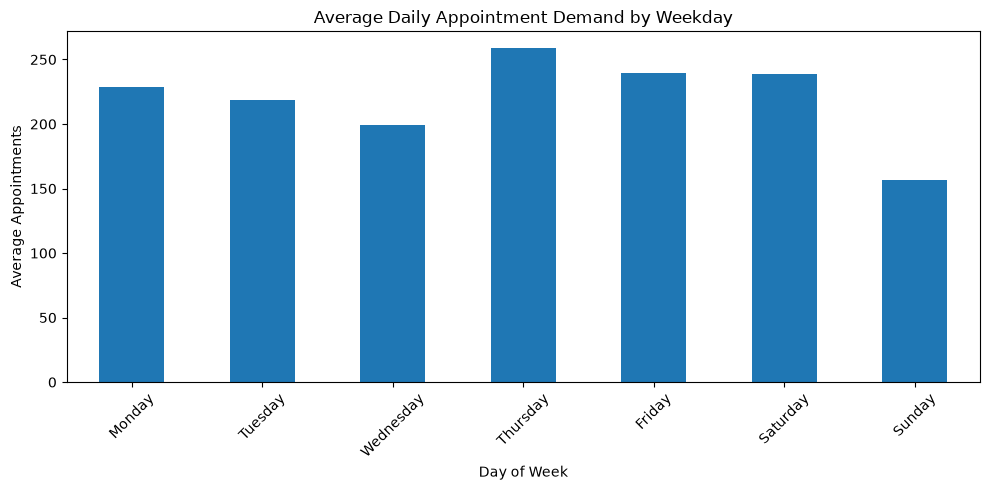

In [45]:
plt.figure(figsize=(10, 5))

weekday_demand.plot(kind='bar')

plt.title("Average Daily Appointment Demand by Weekday")
plt.xlabel("Day of Week")
plt.ylabel("Average Appointments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

<Figure size 1200x500 with 0 Axes>

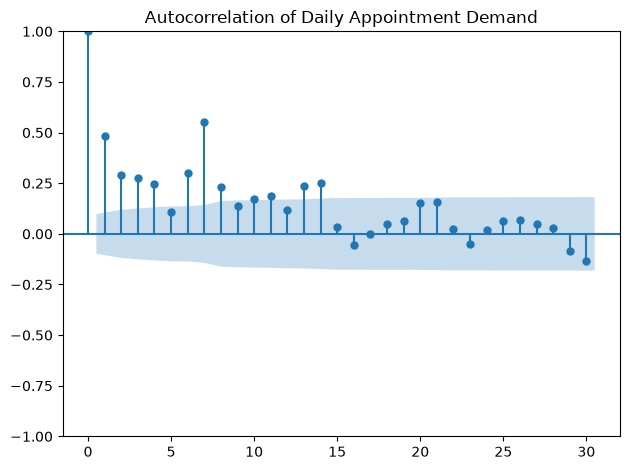

In [46]:
from statsmodels.graphics.tsaplots import plot_acf

plt.figure(figsize=(12, 5))

plot_acf(
    train_data['appointment_count'],
    lags=30
)

plt.title("Autocorrelation of Daily Appointment Demand")
plt.tight_layout()
plt.show()

In [47]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(
    train_data['appointment_count']
)

print("ADF Statistic:", adf_result[0])
print("P-value:", adf_result[1])

ADF Statistic: -3.899384745842865
P-value: 0.0020393797067711533


C:\Users\sadhu\AppData\Local\Temp\ipykernel_17316\2515920534.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(


In [48]:
adf_result = adfuller(
    train_data['appointment_count'],
    result_object=True
)

print("ADF Statistic:", adf_result.statistic)
print("P-value:", adf_result.pvalue)

ADF Statistic: -3.899384745842865
P-value: 0.0020393797067711533


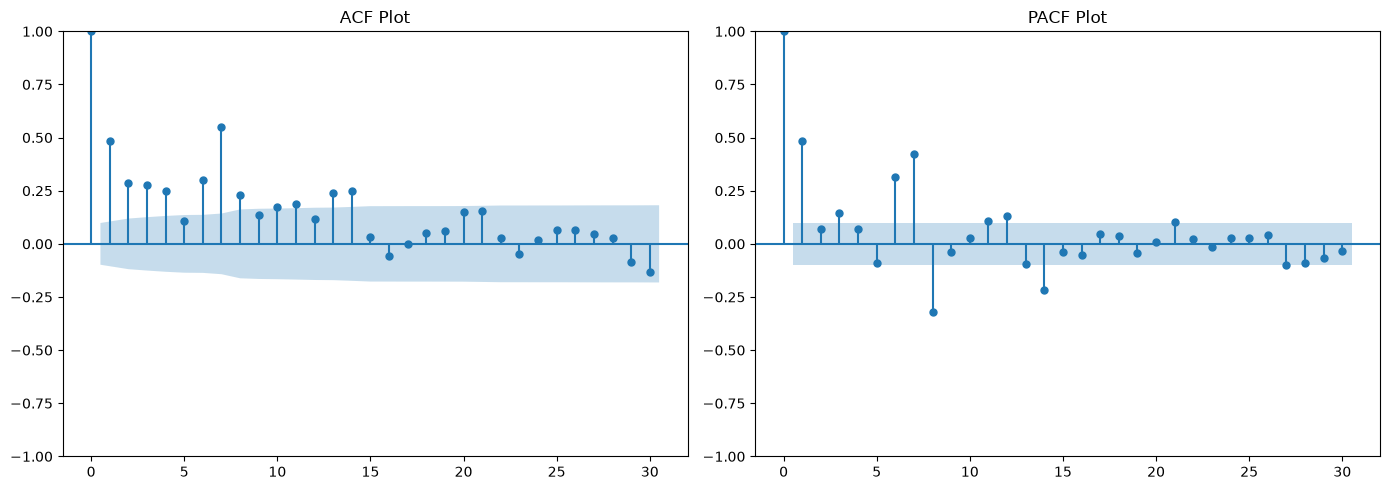

In [49]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(
    train_data['appointment_count'],
    lags=30,
    ax=axes[0]
)

plot_pacf(
    train_data['appointment_count'],
    lags=30,
    ax=axes[1],
    method='ywm'
)

axes[0].set_title("ACF Plot")
axes[1].set_title("PACF Plot")

plt.tight_layout()
plt.show()

In [50]:
from statsmodels.tsa.arima.model import ARIMA

arima_model = ARIMA(
    train_data['appointment_count'],
    order=(1, 0, 1)
)

arima_result = arima_model.fit()

arima_predictions = arima_result.forecast(
    steps=len(test_data)
)

print(arima_predictions.head(10))

398    149.356928
399    166.542069
400    179.730681
401    189.852187
402    197.619863
403    203.581110
404    208.156027
405    211.667013
406    214.361495
407    216.429355
Name: predicted_mean, dtype: float64


In [51]:
actual = test_data['appointment_count'].to_numpy()

arima_mae = mean_absolute_error(
    actual, arima_predictions
)

arima_rmse = np.sqrt(
    mean_squared_error(actual, arima_predictions)
)

non_zero_mask = actual != 0

arima_mape = np.mean(
    np.abs(
        (actual[non_zero_mask] -
         arima_predictions.to_numpy()[non_zero_mask])
        / actual[non_zero_mask]
    )
) * 100

arima_r2 = r2_score(
    actual, arima_predictions
)

print("ARIMA MAE:", arima_mae)
print("ARIMA RMSE:", arima_rmse)
print("ARIMA MAPE:", arima_mape)
print("ARIMA R2:", arima_r2)

ARIMA MAE: 234.9517440504784
ARIMA RMSE: 287.4465181514267
ARIMA MAPE: 4608.675377505891
ARIMA R2: -0.023144904432919722


In [52]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima_model = SARIMAX(
    train_data['appointment_count'],
    order=(1, 0, 1),
    seasonal_order=(1, 0, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_result = sarima_model.fit(disp=False)

sarima_predictions = sarima_result.forecast(
    steps=len(test_data)
)

print(sarima_predictions.head(10))

398    391.281586
399    245.196079
400    254.187589
401    363.005187
402    330.875824
403     26.895342
404     20.765793
405    211.383236
406    133.664705
407    136.700953
Name: predicted_mean, dtype: float64


In [53]:
actual = test_data['appointment_count'].to_numpy()
predicted = sarima_predictions.to_numpy()

sarima_mae = mean_absolute_error(actual, predicted)

sarima_rmse = np.sqrt(
    mean_squared_error(actual, predicted)
)

non_zero_mask = actual != 0

sarima_mape = np.mean(
    np.abs(
        (actual[non_zero_mask] - predicted[non_zero_mask])
        / actual[non_zero_mask]
    )
) * 100

sarima_r2 = r2_score(actual, predicted)

print("SARIMA MAE:", sarima_mae)
print("SARIMA RMSE:", sarima_rmse)
print("SARIMA MAPE:", sarima_mape)
print("SARIMA R2:", sarima_r2)

SARIMA MAE: 172.2489168214346
SARIMA RMSE: 312.6466276648111
SARIMA MAPE: 82.94652918330863
SARIMA R2: -0.21040452340039684


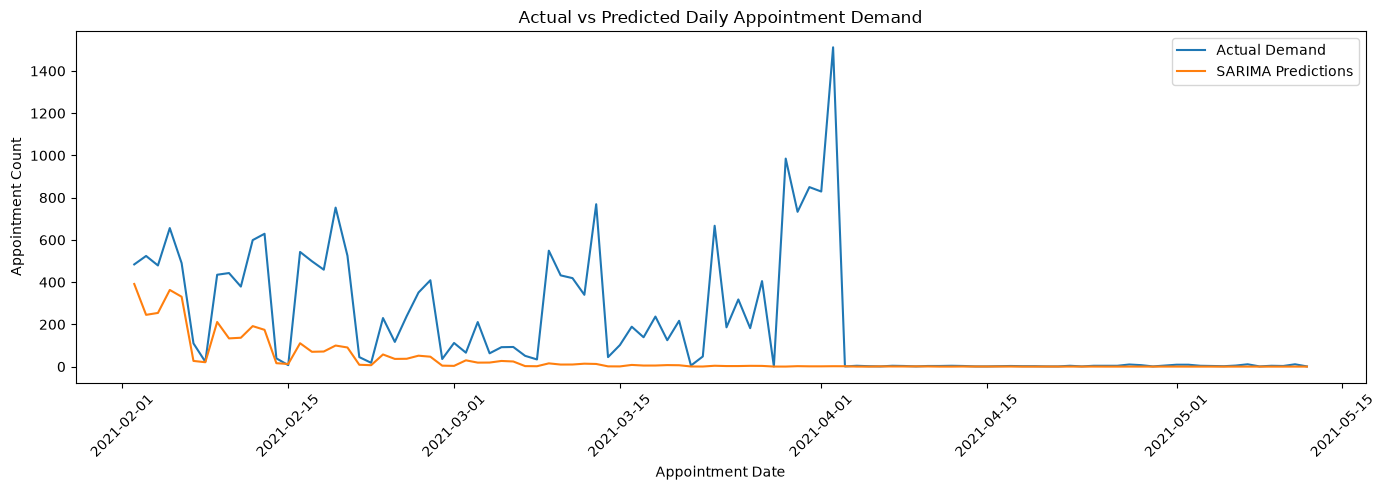

In [54]:
plt.figure(figsize=(14, 5))

plt.plot(
    test_data['appointment_date_continuous'],
    actual,
    label='Actual Demand'
)

plt.plot(
    test_data['appointment_date_continuous'],
    sarima_predictions,
    label='SARIMA Predictions'
)

plt.title('Actual vs Predicted Daily Appointment Demand')
plt.xlabel('Appointment Date')
plt.ylabel('Appointment Count')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [55]:
model_comparison = pd.DataFrame({
    'Model': [
        'Naive',
        'Moving Average',
        'SES',
        'Holt',
        'Holt-Winters',
        'ARIMA',
        'SARIMA'
    ],
    'MAE': [
        naive_mae,
        moving_average_mae,
        ses_mae,
        holt_mae,
        hw_mae,
        arima_mae,
        sarima_mae
    ],
    'RMSE': [
        naive_rmse,
        moving_average_rmse,
        ses_rmse,
        holt_rmse,
        hw_rmse,
        arima_rmse,
        sarima_rmse
    ],
    'MAPE': [
        naive_mape,
        moving_average_mape,
        ses_mape,
        holt_mape,
        hw_mape,
        arima_mape,
        sarima_mape
    ],
    'R2': [
        naive_r2,
        moving_average_r2,
        ses_r2,
        holt_r2,
        hw_r2,
        arima_r2,
        sarima_r2
    ]
})

model_comparison

NameError: name 'naive_mae' is not defined

In [56]:
def evaluate_model(actual, predictions):
    actual = np.asarray(actual)
    predictions = np.asarray(predictions)

    non_zero_mask = actual != 0

    return {
        'MAE': mean_absolute_error(actual, predictions),
        'RMSE': np.sqrt(mean_squared_error(actual, predictions)),
        'MAPE': np.mean(
            np.abs(
                (actual[non_zero_mask] - predictions[non_zero_mask])
                / actual[non_zero_mask]
            )
        ) * 100,
        'R2': r2_score(actual, predictions)
    }


actual = test_data['appointment_count'].to_numpy()

model_predictions = {
    'Naive': naive_predictions,
    'Moving Average': moving_average_predictions,
    'SES': ses_predictions,
    'Holt': holt_predictions,
    'Holt-Winters': hw_predictions,
    'ARIMA': arima_predictions,
    'SARIMA': sarima_predictions
}

results = []

for model_name, predictions in model_predictions.items():
    metrics = evaluate_model(actual, predictions)

    results.append({
        'Model': model_name,
        **metrics
    })

model_comparison = pd.DataFrame(results)

model_comparison.round(2)

,Model,MAE,RMSE,MAPE,R2
0,Naive,200.34,337.85,494.90,-0.41
1,Moving Average,282.04,316.85,7183.31,-0.24
2,SES,240.85,286.84,5076.15,-0.02
3,Holt,261.18,300.39,6031.66,-0.12
4,Holt-Winters,253.33,313.39,7555.56,-0.22
5,ARIMA,234.95,287.45,4608.68,-0.02
6,SARIMA,172.25,312.65,82.95,-0.21


In [57]:
model_comparison[['Model', 'MAPE']].round(2)

,Model,MAPE
0,Naive,494.90
1,Moving Average,7183.31
2,SES,5076.15
3,Holt,6031.66
4,Holt-Winters,7555.56
5,ARIMA,4608.68
6,SARIMA,82.95


In [58]:
actual = test_data['appointment_count'].to_numpy()
non_zero_mask = actual != 0

for name, predictions in model_predictions.items():

    predictions = np.asarray(predictions)

    mape = np.mean(
        np.abs(
            (actual[non_zero_mask] - predictions[non_zero_mask])
            / actual[non_zero_mask]
        )
    ) * 100

    print(f"{name}: {mape:.2f}%")

Naive: 494.90%
Moving Average: 7183.31%
SES: 5076.15%
Holt: 6031.66%
Holt-Winters: 7555.56%
ARIMA: 4608.68%
SARIMA: 82.95%


In [59]:
print("Test Data Demand Summary:")
print(test_data['appointment_count'].describe())

print("\nDays with zero appointments:")
print((test_data['appointment_count'] == 0).sum())

print("\nDays with fewer than 10 appointments:")
print((test_data['appointment_count'] < 10).sum())

Test Data Demand Summary:
count     100.000000
mean      206.720000
std       285.608338
min         1.000000
25%         4.000000
50%        46.500000
75%       406.000000
max      1512.000000
Name: appointment_count, dtype: float64

Days with zero appointments:
0

Days with fewer than 10 appointments:
40


In [60]:
test_data['month_year'] = (
    test_data['appointment_date_continuous']
    .dt.to_period('M')
)

monthly_test_demand = (
    test_data.groupby('month_year')['appointment_count']
    .agg(['mean', 'median', 'min', 'max', 'sum'])
)

monthly_test_demand

,mean,median,min,max,sum
month_year,,,,,
2021-02,352.629630,435.0,7,753,9521
2021-03,279.516129,186.0,1,985,8665
2021-04,80.766667,3.0,1,1512,2423
2021-05,5.250000,4.0,1,11,63


In [61]:
print(
    daily_demand[
        ['appointment_date_continuous', 'appointment_count']
    ].tail(30).to_string(index=False)
)

appointment_date_continuous  appointment_count
                 2021-04-13                  3
                 2021-04-14                  1
                 2021-04-15                  1
                 2021-04-16                  2
                 2021-04-17                  3
                 2021-04-18                  2
                 2021-04-19                  2
                 2021-04-20                  1
                 2021-04-21                  1
                 2021-04-22                  4
                 2021-04-23                  1
                 2021-04-24                  4
                 2021-04-25                  4
                 2021-04-26                  4
                 2021-04-27                 10
                 2021-04-28                  7
                 2021-04-29                  1
                 2021-04-30                  5
                 2021-05-01                  9
                 2021-05-02                  9
             

In [62]:
april_specialty = (
    specialty_daily_demand[
        specialty_daily_demand['appointment_date_continuous']
        >= '2021-04-01'
    ]
    .groupby('specialty')['appointment_count']
    .sum()
    .sort_values(ascending=False)
)

print(april_specialty)

specialty
psychotherapy           663
speech therapy          515
physiotherapy           492
Unknown                 430
occupational therapy    244
pedagogo                 75
enf                      43
sem especialidade        14
assist                   10
Name: appointment_count, dtype: int64


In [63]:
specialty_monthly = specialty_daily_demand.copy()

specialty_monthly['month'] = (
    specialty_monthly['appointment_date_continuous']
    .dt.to_period('M')
)

specialty_monthly = (
    specialty_monthly[
        specialty_monthly['month'].isin(
            ['2021-03', '2021-04', '2021-05']
        )
    ]
    .groupby(['specialty', 'month'])['appointment_count']
    .sum()
    .unstack(fill_value=0)
)

specialty_monthly

month
specialty


In [64]:
print(specialty_monthly.to_string())

Empty DataFrame
Columns: []
Index: []


In [65]:
print(
    specialty_daily_demand[
        'appointment_date_continuous'
    ].dt.to_period('M').unique()
)

<PeriodArray>
['2020-01', '2020-02', '2020-03', '2020-04', '2020-05', '2020-06', '2020-07',
 '2020-08', '2020-09', '2020-10', '2020-11', '2020-12', '2021-01', '2021-02',
 '2021-03', '2021-04', '2021-05']
Length: 17, dtype: period[M]


In [66]:
specialty_monthly = specialty_daily_demand.copy()

specialty_monthly['month'] = (
    specialty_monthly['appointment_date_continuous']
    .dt.to_period('M')
)

selected_months = pd.PeriodIndex(
    ['2021-03', '2021-04', '2021-05'],
    freq='M'
)

specialty_monthly = (
    specialty_monthly[
        specialty_monthly['month'].isin(selected_months)
    ]
    .groupby(['specialty', 'month'])['appointment_count']
    .sum()
    .unstack(fill_value=0)
)

print(specialty_monthly)

month                 2021-03  2021-04  2021-05
specialty                                      
Unknown                  1564      424        6
assist                     50        9        1
enf                       130       43        0
occupational therapy      920      238        6
pedagogo                  293       73        2
physiotherapy            1662      482       10
psychotherapy            2235      639       24
sem especialidade          28       14        0
speech therapy           1783      501       14


In [67]:
print(
    df[
        df['appointment_date_continuous'].between(
            '2021-03-25', '2021-04-15'
        )
    ]['appointment_date_continuous']
    .value_counts()
    .sort_index()
)

appointment_date_continuous
2021-03-25     318
2021-03-26     182
2021-03-27     405
2021-03-28       1
2021-03-29     985
2021-03-30     733
2021-03-31     850
2021-04-01     829
2021-04-02    1512
2021-04-03       1
2021-04-04       4
2021-04-05       2
2021-04-06       1
2021-04-07       4
2021-04-08       3
2021-04-09       1
2021-04-10       3
2021-04-11       3
2021-04-12       4
2021-04-13       3
2021-04-14       1
2021-04-15       1
Name: count, dtype: int64


In [68]:
print(df.dtypes)

specialty                                 str
appointment_time                        int64
gender                                    str
no_show                                   str
disability                                str
place                                     str
appointment_shift                         str
age                                   float64
under_12_years_old                      int64
over_60_years_old                       int64
patient_needs_companion                 int64
average_temp_day                      float64
average_rain_day                      float64
max_temp_day                          float64
max_rain_day                          float64
rainy_day_before                        int64
storm_day_before                        int64
rain_intensity                            str
heat_intensity                            str
appointment_date_continuous    datetime64[us]
Hipertension                            int64
Diabetes                          

In [69]:
print("April 2 records:")
print(
    df[df['appointment_date_continuous'] == '2021-04-02'].shape
)

print("\nApril 3 records:")
print(
    df[df['appointment_date_continuous'] == '2021-04-03'].shape
)

print("\nTotal records:")
print(df.shape)

April 2 records:
(1512, 26)

April 3 records:
(1, 26)

Total records:
(109593, 26)


In [70]:
print("April 2 records:")
print(
    df[df['appointment_date_continuous'] == '2021-04-02'].shape
)

print("\nApril 3 records:")
print(
    df[df['appointment_date_continuous'] == '2021-04-03'].shape
)

print("\nTotal records:")
print(df.shape)

April 2 records:
(1512, 26)

April 3 records:
(1, 26)

Total records:
(109593, 26)


In [71]:
status_daily = (
    df.groupby([
        'appointment_date_continuous',
        'no_show'
    ])
    .size()
    .unstack(fill_value=0)
)

print(status_daily.loc['2021-03-25':'2021-04-15'])

no_show                        no  yes
appointment_date_continuous           
2021-03-25                    226   92
2021-03-26                    120   62
2021-03-27                    295  110
2021-03-28                      0    1
2021-03-29                    691  294
2021-03-30                    489  244
2021-03-31                    591  259
2021-04-01                    573  256
2021-04-02                   1033  479
2021-04-03                      1    0
2021-04-04                      3    1
2021-04-05                      1    1
2021-04-06                      1    0
2021-04-07                      2    2
2021-04-08                      1    2
2021-04-09                      1    0
2021-04-10                      2    1
2021-04-11                      2    1
2021-04-12                      2    2
2021-04-13                      2    1
2021-04-14                      1    0
2021-04-15                      1    0


In [72]:
print("Unique place values:")
print(df['place'].nunique())

print("\nMost common place values:")
print(df['place'].value_counts().head(10))

Unique place values:
26289

Most common place values:
place
ITAJAÍ            20515
B. CAMBORIU        6018
CAMBORIU           5523
NAVEGANTES         3901
ITAPEMA            2665
BOMBINHAS          1707
PENHA              1039
PORTO BELO          950
BALN. PIÇARRAS      945
ILHOTA              583
Name: count, dtype: int64


In [73]:
df['month'] = df['appointment_date_continuous'].dt.to_period('M')

place_monthly = (
    df[df['month'].isin(
        pd.PeriodIndex(['2021-03', '2021-04'], freq='M')
    )]
    .groupby(['place', 'month'])
    .size()
    .unstack(fill_value=0)
)

place_monthly['change'] = (
    place_monthly['2021-04'] - place_monthly['2021-03']
)

print(
    place_monthly.sort_values(
        '2021-03', ascending=False
    ).head(10)
)

KeyError: '2021-03'

In [74]:
place_monthly = (
    df[df['appointment_date_continuous'].between(
        '2021-03-01', '2021-04-30'
    )]
    .assign(
        month=lambda x: x['appointment_date_continuous'].dt.strftime('%Y-%m')
    )
    .groupby(['place', 'month'])
    .size()
    .unstack(fill_value=0)
)

print("Available columns:")
print(place_monthly.columns.tolist())

print("\nTop 10 places:")
print(
    place_monthly.sort_values(
        by='2021-03',
        ascending=False
    ).head(10)
)

Available columns:
['2021-03', '2021-04']

Top 10 places:
month           2021-03  2021-04
place                           
ITAJAÍ             1699      446
B. CAMBORIU         475      142
CAMBORIU            431      104
NAVEGANTES          308       98
ITAPEMA             213       58
BOMBINHAS           143       48
PORTO BELO           84       21
BALN. PIÇARRAS       83       23
PENHA                75       30
ILHOTA               43       15


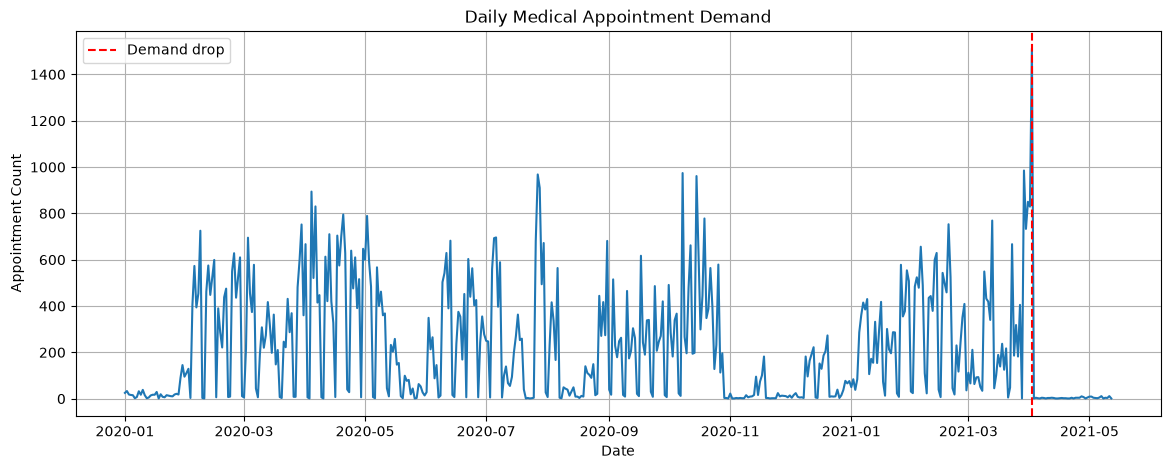

In [75]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    overall_demand['appointment_date_continuous'],
    overall_demand['appointment_count']
)

plt.axvline(
    pd.Timestamp('2021-04-02'),
    color='red',
    linestyle='--',
    label='Demand drop'
)

plt.title('Daily Medical Appointment Demand')
plt.xlabel('Date')
plt.ylabel('Appointment Count')
plt.legend()
plt.grid()
plt.show()

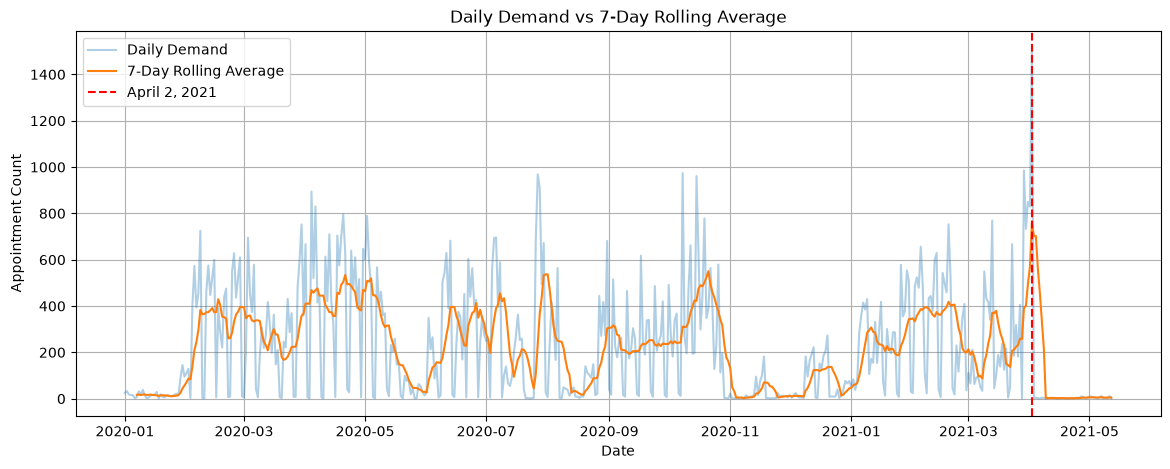

In [76]:
overall_demand['rolling_7day_avg'] = (
    overall_demand['appointment_count']
    .rolling(window=7)
    .mean()
)

plt.figure(figsize=(14, 5))

plt.plot(
    overall_demand['appointment_date_continuous'],
    overall_demand['appointment_count'],
    alpha=0.35,
    label='Daily Demand'
)

plt.plot(
    overall_demand['appointment_date_continuous'],
    overall_demand['rolling_7day_avg'],
    label='7-Day Rolling Average'
)

plt.axvline(
    pd.Timestamp('2021-04-02'),
    color='red',
    linestyle='--',
    label='April 2, 2021'
)

plt.title('Daily Demand vs 7-Day Rolling Average')
plt.xlabel('Date')
plt.ylabel('Appointment Count')
plt.legend()
plt.grid()
plt.show()

In [77]:
overall_demand['period'] = (
    overall_demand['appointment_date_continuous']
    .apply(
        lambda x: 'Before April 2'
        if x < '2021-04-02'
        else 'From April 2'
    )
)

period_comparison = (
    overall_demand.groupby('period')['appointment_count']
    .agg(['count', 'mean', 'median', 'min', 'max'])
)

print(period_comparison)

TypeError: '<' not supported between instances of 'Timestamp' and 'str'

In [78]:
overall_demand['period'] = (
    overall_demand['appointment_date_continuous']
    .apply(
        lambda x: 'Before April 2'
        if x < pd.Timestamp('2021-04-02')
        else 'From April 2'
    )
)

period_comparison = (
    overall_demand.groupby('period')['appointment_count']
    .agg(['count', 'mean', 'median', 'min', 'max'])
)

print(period_comparison)

                count        mean  median  min   max
period                                              
Before April 2    457  236.183807   174.0    1   985
From April 2       41   40.414634     3.0    1  1512


In [79]:
monthly_demand = (
    overall_demand
    .set_index('appointment_date_continuous')
    ['appointment_count']
    .resample('ME')
    .sum()
)

print(monthly_demand)

appointment_date_continuous
2020-01-31      772
2020-02-29     9998
2020-03-31     8796
2020-04-30    13042
2020-05-31     6176
2020-06-30     8785
2020-07-31     9043
2020-08-31     4712
2020-09-30     6375
2020-10-31    10739
2020-11-30      649
2020-12-31     2241
2021-01-31     7569
2021-02-28     9545
2021-03-31     8665
2021-04-30     2423
2021-05-31       63
Freq: ME, Name: appointment_count, dtype: int64


In [80]:
monthly_check = (
    overall_demand
    .set_index('appointment_date_continuous')
    .resample('ME')
    .agg(
        total_appointments=('appointment_count', 'sum'),
        recorded_days=('appointment_count', 'count')
    )
)

print(monthly_check)

                             total_appointments  recorded_days
appointment_date_continuous                                   
2020-01-31                                  772             31
2020-02-29                                 9998             29
2020-03-31                                 8796             31
2020-04-30                                13042             30
2020-05-31                                 6176             31
2020-06-30                                 8785             30
2020-07-31                                 9043             31
2020-08-31                                 4712             31
2020-09-30                                 6375             30
2020-10-31                                10739             31
2020-11-30                                  649             30
2020-12-31                                 2241             31
2021-01-31                                 7569             31
2021-02-28                                 9545        

In [81]:
monthly_check['average_daily_demand'] = (
    monthly_check['total_appointments'] /
    monthly_check['recorded_days']
)

print(
    monthly_check[
        ['average_daily_demand']
    ].round(2)
)

                             average_daily_demand
appointment_date_continuous                      
2020-01-31                                  24.90
2020-02-29                                 344.76
2020-03-31                                 283.74
2020-04-30                                 434.73
2020-05-31                                 199.23
2020-06-30                                 292.83
2020-07-31                                 291.71
2020-08-31                                 152.00
2020-09-30                                 212.50
2020-10-31                                 346.42
2020-11-30                                  21.63
2020-12-31                                  72.29
2021-01-31                                 244.16
2021-02-28                                 340.89
2021-03-31                                 279.52
2021-04-30                                  80.77
2021-05-31                                   5.25


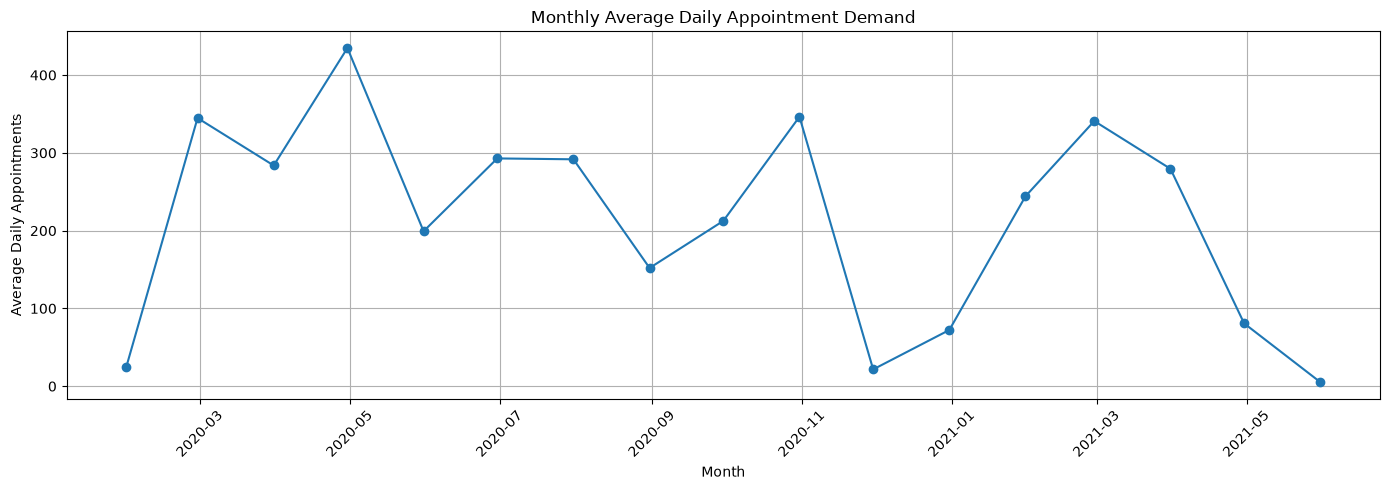

In [82]:
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_check.index,
    monthly_check['average_daily_demand'],
    marker='o'
)

plt.title('Monthly Average Daily Appointment Demand')
plt.xlabel('Month')
plt.ylabel('Average Daily Appointments')
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

In [83]:
df['month'] = (
    df['appointment_date_continuous']
    .dt.to_period('M')
)

monthly_attendance = (
    df.groupby(['month', 'no_show'])
    .size()
    .unstack(fill_value=0)
)

print(monthly_attendance)

no_show    no   yes
month              
2020-01   519   253
2020-02  6826  3172
2020-03  6015  2781
2020-04  8873  4169
2020-05  4162  2014
2020-06  5980  2805
2020-07  6122  2921
2020-08  3200  1512
2020-09  4366  2009
2020-10  7297  3442
2020-11   441   208
2020-12  1473   768
2021-01  5227  2342
2021-02  6551  2994
2021-03  6009  2656
2021-04  1660   763
2021-05    40    23


In [84]:
monthly_attendance['total_appointments'] = (
    monthly_attendance['no'] +
    monthly_attendance['yes']
)

monthly_attendance['no_show_rate'] = (
    monthly_attendance['yes'] /
    monthly_attendance['total_appointments']
) * 100

print(
    monthly_attendance[
        ['total_appointments', 'no_show_rate']
    ].round(2)
)

no_show  total_appointments  no_show_rate
month                                    
2020-01                 772         32.77
2020-02                9998         31.73
2020-03                8796         31.62
2020-04               13042         31.97
2020-05                6176         32.61
2020-06                8785         31.93
2020-07                9043         32.30
2020-08                4712         32.09
2020-09                6375         31.51
2020-10               10739         32.05
2020-11                 649         32.05
2020-12                2241         34.27
2021-01                7569         30.94
2021-02                9545         31.37
2021-03                8665         30.65
2021-04                2423         31.49
2021-05                  63         36.51


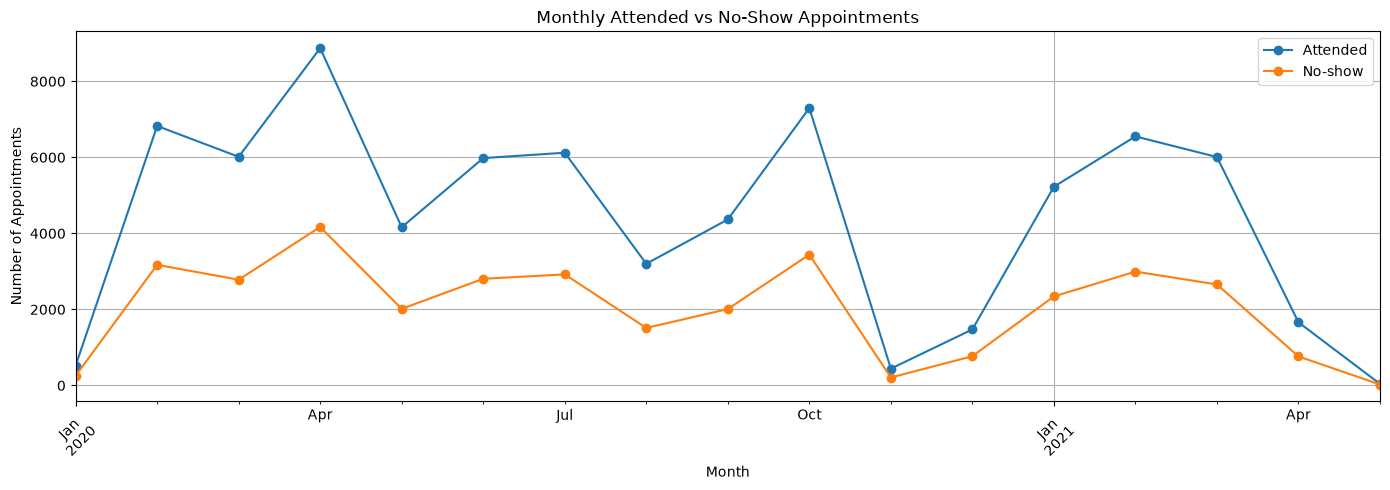

In [85]:
monthly_attendance[['no', 'yes']].plot(
    kind='line',
    figsize=(14, 5),
    marker='o'
)

plt.title('Monthly Attended vs No-Show Appointments')
plt.xlabel('Month')
plt.ylabel('Number of Appointments')
plt.legend(['Attended', 'No-show'])
plt.grid()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [86]:
monthly_specialty = (
    df.groupby([
        df['appointment_date_continuous'].dt.to_period('M'),
        'specialty'
    ])
    .size()
    .unstack(fill_value=0)
)

print(monthly_specialty)

specialty                    assist  enf  occupational therapy  pedagogo  \
appointment_date_continuous                                                
2020-01                           7   16                    85        24   
2020-02                          66  159                  1029       324   
2020-03                          69  139                   938       282   
2020-04                          77  191                  1389       432   
2020-05                          34  108                   598       204   
2020-06                          43  109                   903       303   
2020-07                          47  154                   926       290   
2020-08                          21   71                   487       146   
2020-09                          38  104                   633       214   
2020-10                          59  142                  1102       341   
2020-11                           3   12                    62        21   
2020-12     

In [87]:
specialty_change = pd.DataFrame({
    'March_2021': monthly_specialty.loc['2021-03'],
    'April_2021': monthly_specialty.loc['2021-04']
})

specialty_change['percentage_change'] = (
    (specialty_change['April_2021'] -
     specialty_change['March_2021']) /
    specialty_change['March_2021']
) * 100

print(
    specialty_change.sort_values(
        'percentage_change'
    ).round(2)
)

                      March_2021  April_2021  percentage_change
specialty                                                      
assist                        50           9             -82.00
pedagogo                     293          73             -75.09
occupational therapy         920         238             -74.13
speech therapy              1783         501             -71.90
psychotherapy               2235         639             -71.41
physiotherapy               1662         482             -71.00
enf                          130          43             -66.92
sem especialidade             28          14             -50.00


In [88]:
date_check = pd.date_range(
    start=df['appointment_date_continuous'].min(),
    end=df['appointment_date_continuous'].max(),
    freq='D'
)

existing_dates = df['appointment_date_continuous'].dt.normalize().unique()

missing_dates = date_check.difference(existing_dates)

print("Expected calendar days:", len(date_check))
print("Dates present:", len(existing_dates))
print("Missing dates:", len(missing_dates))
print("Missing dates:", missing_dates)

Expected calendar days: 498
Dates present: 498
Missing dates: 0
Missing dates: DatetimeIndex([], dtype='datetime64[us]', freq='D')


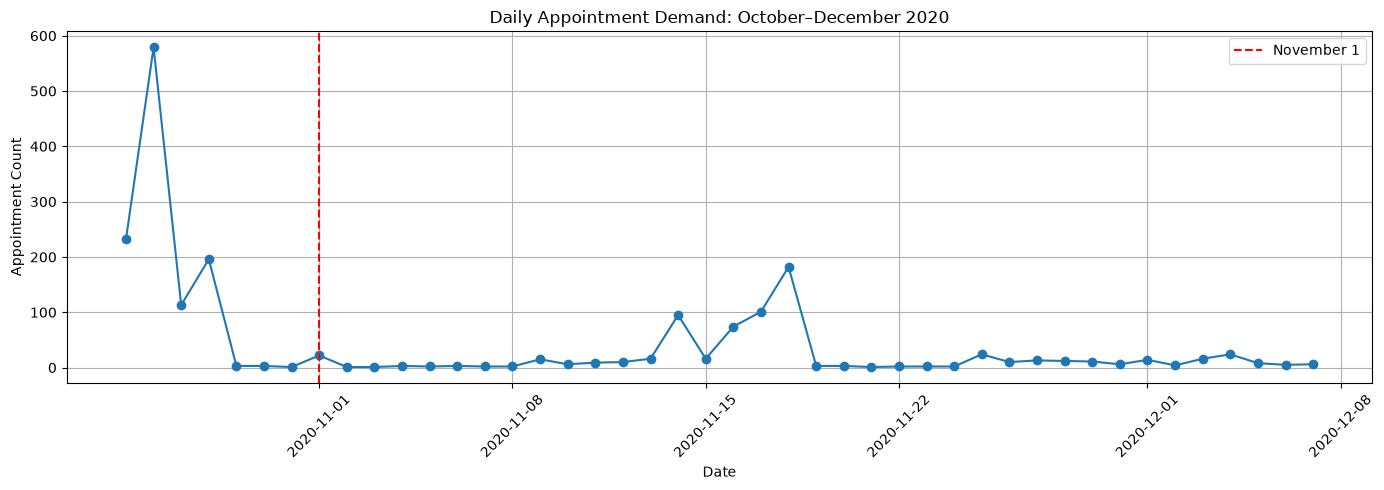

In [89]:
november_demand = overall_demand[
    overall_demand['appointment_date_continuous'].between(
        '2020-10-25', '2020-12-07'
    )
]

plt.figure(figsize=(14, 5))

plt.plot(
    november_demand['appointment_date_continuous'],
    november_demand['appointment_count'],
    marker='o'
)

plt.axvline(
    pd.Timestamp('2020-11-01'),
    color='red',
    linestyle='--',
    label='November 1'
)

plt.title('Daily Appointment Demand: October–December 2020')
plt.xlabel('Date')
plt.ylabel('Appointment Count')
plt.legend()
plt.grid()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [90]:
monthly_check.loc[
    ['2020-10', '2020-11', '2020-12'],
    ['total_appointments', 'average_daily_demand']
].round(2)

KeyError: "None of [Index(['2020-10', '2020-11', '2020-12'], dtype='str', name='appointment_date_continuous')] are in the [index]"

In [91]:
monthly_check.loc[
    [
        pd.Timestamp('2020-10-31'),
        pd.Timestamp('2020-11-30'),
        pd.Timestamp('2020-12-31')
    ],
    ['total_appointments', 'average_daily_demand']
].round(2)

,total_appointments,average_daily_demand
appointment_date_continuous,,
2020-10-31,10739,346.42
2020-11-30,649,21.63
2020-12-31,2241,72.29


In [92]:
november_stats = (
    overall_demand[
        overall_demand['appointment_date_continuous'].dt.month == 11
    ]['appointment_count']
    .describe()
)

print(november_stats)

count     30.000000
mean      21.633333
std       40.014207
min        1.000000
25%        2.000000
50%        7.500000
75%       15.750000
max      182.000000
Name: appointment_count, dtype: float64


In [93]:
low_demand_comparison = overall_demand[
    (
        (overall_demand['appointment_date_continuous'].dt.year == 2020) &
        (overall_demand['appointment_date_continuous'].dt.month == 11)
    ) |
    (
        (overall_demand['appointment_date_continuous'].dt.year == 2021) &
        (overall_demand['appointment_date_continuous'].dt.month == 4)
    )
].copy()

low_demand_comparison['period'] = (
    low_demand_comparison['appointment_date_continuous']
    .dt.strftime('%Y-%m')
)

print(
    low_demand_comparison.groupby('period')['appointment_count']
    .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
    .round(2)
)

         count   mean  median     std  min   max
period                                          
2020-11     30  21.63     7.5   40.01    1   182
2021-04     30  80.77     3.0  309.51    1  1512


In [94]:
low_demand_days = (
    low_demand_comparison
    .groupby('period')['appointment_count']
    .agg(
        total_days='count',
        days_below_10=lambda x: (x < 10).sum()
    )
)

low_demand_days['percentage_below_10'] = (
    low_demand_days['days_below_10'] /
    low_demand_days['total_days']
) * 100

print(low_demand_days.round(2))

         total_days  days_below_10  percentage_below_10
period                                                 
2020-11          30             16                53.33
2021-04          30             27                90.00


In [95]:
monthly_check['demand_change_pct'] = (
    monthly_check['total_appointments']
    .pct_change() * 100
)

print(
    monthly_check[
        ['total_appointments', 'demand_change_pct']
    ].round(2)
)

                             total_appointments  demand_change_pct
appointment_date_continuous                                       
2020-01-31                                  772                NaN
2020-02-29                                 9998            1195.08
2020-03-31                                 8796             -12.02
2020-04-30                                13042              48.27
2020-05-31                                 6176             -52.65
2020-06-30                                 8785              42.24
2020-07-31                                 9043               2.94
2020-08-31                                 4712             -47.89
2020-09-30                                 6375              35.29
2020-10-31                                10739              68.45
2020-11-30                                  649             -93.96
2020-12-31                                 2241             245.30
2021-01-31                                 7569             23

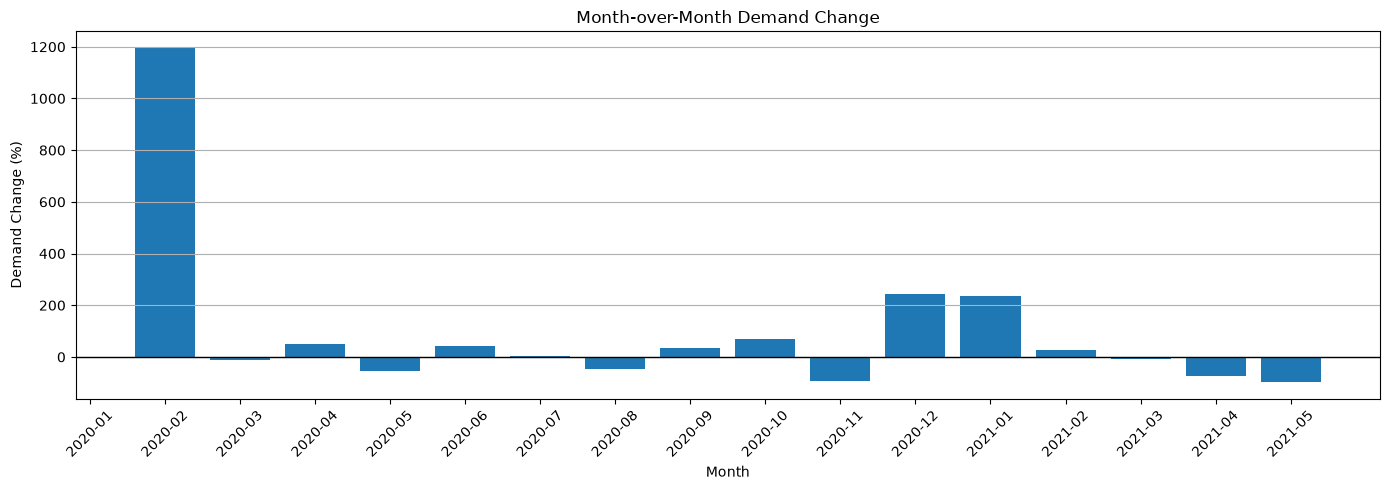

In [96]:
plt.figure(figsize=(14, 5))

plt.bar(
    monthly_check.index.strftime('%Y-%m'),
    monthly_check['demand_change_pct']
)

plt.axhline(0, color='black', linewidth=1)

plt.title('Month-over-Month Demand Change')
plt.xlabel('Month')
plt.ylabel('Demand Change (%)')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

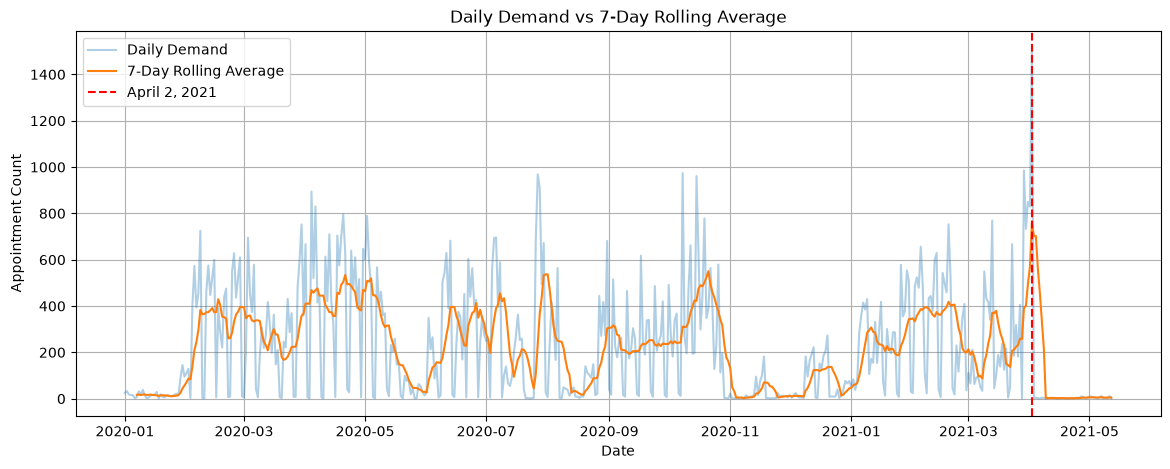

In [97]:
overall_demand['rolling_7day_avg'] = (
    overall_demand['appointment_count']
    .rolling(window=7)
    .mean()
)

plt.figure(figsize=(14, 5))

plt.plot(
    overall_demand['appointment_date_continuous'],
    overall_demand['appointment_count'],
    alpha=0.35,
    label='Daily Demand'
)

plt.plot(
    overall_demand['appointment_date_continuous'],
    overall_demand['rolling_7day_avg'],
    label='7-Day Rolling Average'
)

plt.axvline(
    pd.Timestamp('2021-04-02'),
    color='red',
    linestyle='--',
    label='April 2, 2021'
)

plt.title('Daily Demand vs 7-Day Rolling Average')
plt.xlabel('Date')
plt.ylabel('Appointment Count')
plt.legend()
plt.grid()
plt.show()

In [98]:
weekly_demand = (
    overall_demand
    .set_index('appointment_date_continuous')
    ['appointment_count']
    .resample('W-SUN')
    .sum()
    .reset_index()
)

weekly_demand.columns = [
    'week_ending',
    'appointment_count'
]

print(weekly_demand.head())
print("\nShape:", weekly_demand.shape)

  week_ending  appointment_count
0  2020-01-05                107
1  2020-01-12                113
2  2020-01-19                102
3  2020-01-26                 81
4  2020-02-02                609

Shape: (72, 2)


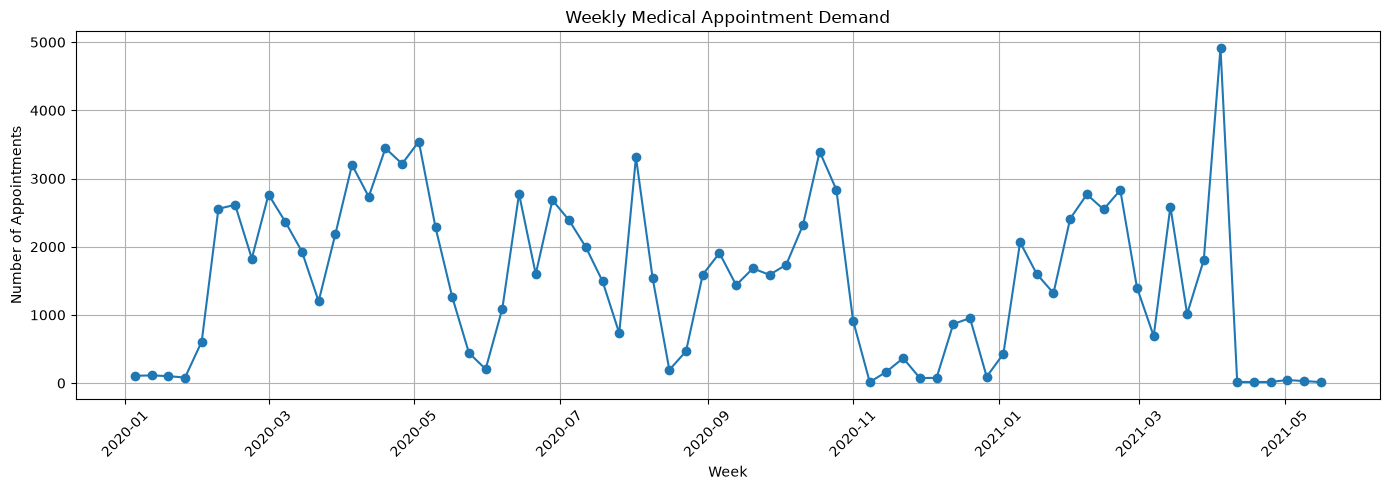

In [99]:
plt.figure(figsize=(14, 5))

plt.plot(
    weekly_demand['week_ending'],
    weekly_demand['appointment_count'],
    marker='o'
)

plt.title('Weekly Medical Appointment Demand')
plt.xlabel('Week')
plt.ylabel('Number of Appointments')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [100]:
split_index = int(len(weekly_demand) * 0.8)

weekly_train = weekly_demand.iloc[:split_index]
weekly_test = weekly_demand.iloc[split_index:]

print("Training data:", weekly_train.shape)
print("Testing data:", weekly_test.shape)

print("\nTraining period:")
print(weekly_train['week_ending'].min(), "to",
      weekly_train['week_ending'].max())

print("\nTesting period:")
print(weekly_test['week_ending'].min(), "to",
      weekly_test['week_ending'].max())

Training data: (57, 2)
Testing data: (15, 2)

Training period:
2020-01-05 00:00:00 to 2021-01-31 00:00:00

Testing period:
2021-02-07 00:00:00 to 2021-05-16 00:00:00


In [101]:
weekly_test = weekly_test.copy()

weekly_test['naive_prediction'] = (
    weekly_demand['appointment_count']
    .shift(1)
    .loc[weekly_test.index]
)

print(weekly_test)

   week_ending  appointment_count  naive_prediction
57  2021-02-07               2767            2412.0
58  2021-02-14               2547            2767.0
59  2021-02-21               2831            2547.0
60  2021-02-28               1400            2831.0
61  2021-03-07                688            1400.0
62  2021-03-14               2588             688.0
63  2021-03-21               1014            2588.0
64  2021-03-28               1807            1014.0
65  2021-04-04               4914            1807.0
66  2021-04-11                 17            4914.0
67  2021-04-18                 16              17.0
68  2021-04-25                 17              16.0
69  2021-05-02                 45              17.0
70  2021-05-09                 30              45.0
71  2021-05-16                 15              30.0


In [102]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

weekly_mae = mean_absolute_error(
    weekly_test['appointment_count'],
    weekly_test['naive_prediction']
)

weekly_rmse = np.sqrt(
    mean_squared_error(
        weekly_test['appointment_count'],
        weekly_test['naive_prediction']
    )
)

weekly_r2 = r2_score(
    weekly_test['appointment_count'],
    weekly_test['naive_prediction']
)

print("Weekly Naive Model")
print("MAE:", round(weekly_mae, 2))
print("RMSE:", round(weekly_rmse, 2))
print("R2 Score:", round(weekly_r2, 4))

Weekly Naive Model
MAE: 1022.2
RMSE: 1696.3
R2 Score: -0.3843


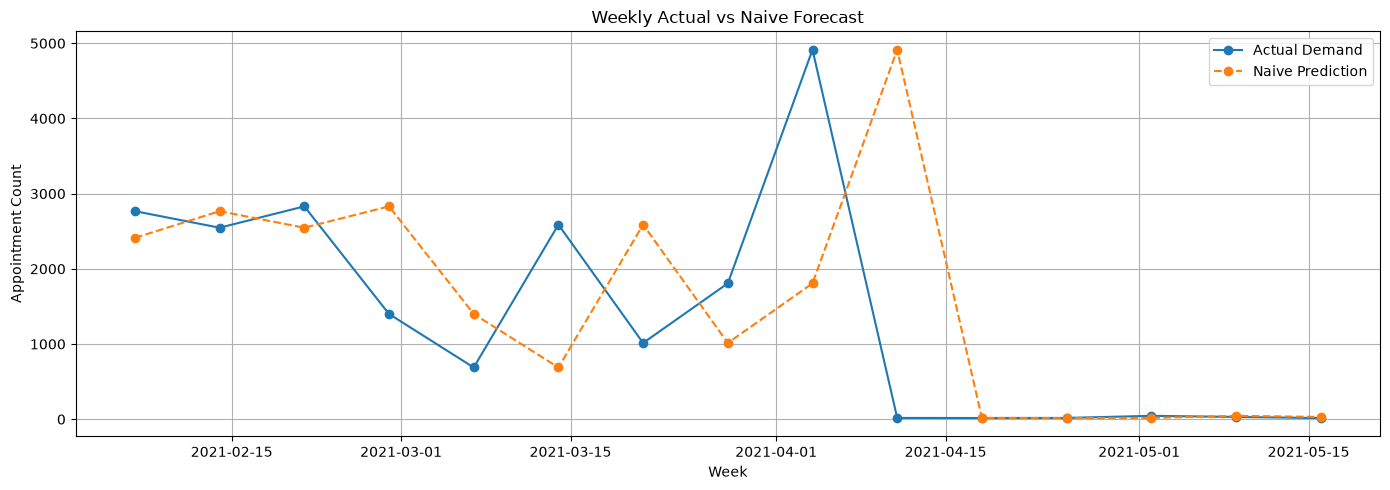

In [103]:
plt.figure(figsize=(14, 5))

plt.plot(
    weekly_test['week_ending'],
    weekly_test['appointment_count'],
    marker='o',
    label='Actual Demand'
)

plt.plot(
    weekly_test['week_ending'],
    weekly_test['naive_prediction'],
    marker='o',
    linestyle='--',
    label='Naive Prediction'
)

plt.title('Weekly Actual vs Naive Forecast')
plt.xlabel('Week')
plt.ylabel('Appointment Count')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [104]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

ses_model = SimpleExpSmoothing(
    weekly_train['appointment_count']
).fit()

weekly_test['ses_prediction'] = ses_model.forecast(
    len(weekly_test)
)

print(
    weekly_test[
        ['week_ending', 'appointment_count', 'ses_prediction']
    ].round(2)
)

TypeError: initialization_method must be a string

In [105]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

ses_model = SimpleExpSmoothing(
    weekly_train['appointment_count'],
    initialization_method='estimated'
).fit()

weekly_test = weekly_test.copy()

weekly_test['ses_prediction'] = ses_model.forecast(
    len(weekly_test)
)

print(
    weekly_test[
        ['week_ending', 'appointment_count', 'ses_prediction']
    ].round(2)
)

   week_ending  appointment_count  ses_prediction
57  2021-02-07               2767         2299.45
58  2021-02-14               2547         2299.45
59  2021-02-21               2831         2299.45
60  2021-02-28               1400         2299.45
61  2021-03-07                688         2299.45
62  2021-03-14               2588         2299.45
63  2021-03-21               1014         2299.45
64  2021-03-28               1807         2299.45
65  2021-04-04               4914         2299.45
66  2021-04-11                 17         2299.45
67  2021-04-18                 16         2299.45
68  2021-04-25                 17         2299.45
69  2021-05-02                 45         2299.45
70  2021-05-09                 30         2299.45
71  2021-05-16                 15         2299.45


C:\Users\sadhu\AppData\Local\Temp\ipykernel_17316\3941006109.py:17: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


In [106]:
ses_mae = mean_absolute_error(
    weekly_test['appointment_count'],
    weekly_test['ses_prediction']
)

ses_rmse = np.sqrt(
    mean_squared_error(
        weekly_test['appointment_count'],
        weekly_test['ses_prediction']
    )
)

ses_r2 = r2_score(
    weekly_test['appointment_count'],
    weekly_test['ses_prediction']
)

print("Weekly SES Model")
print("MAE:", round(ses_mae, 2))
print("RMSE:", round(ses_rmse, 2))
print("R2 Score:", round(ses_r2, 4))

Weekly SES Model
MAE: 1473.02
RMSE: 1710.11
R2 Score: -0.4069


In [107]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

holt_model = ExponentialSmoothing(
    weekly_train['appointment_count'],
    trend='add',
    initialization_method='estimated'
).fit()

weekly_test['holt_prediction'] = holt_model.forecast(
    len(weekly_test)
)

print(
    weekly_test[
        ['week_ending', 'appointment_count', 'holt_prediction']
    ].round(2)
)

   week_ending  appointment_count  holt_prediction
57  2021-02-07               2767          2350.28
58  2021-02-14               2547          2397.90
59  2021-02-21               2831          2445.52
60  2021-02-28               1400          2493.15
61  2021-03-07                688          2540.77
62  2021-03-14               2588          2588.39
63  2021-03-21               1014          2636.02
64  2021-03-28               1807          2683.64
65  2021-04-04               4914          2731.26
66  2021-04-11                 17          2778.89
67  2021-04-18                 16          2826.51
68  2021-04-25                 17          2874.14
69  2021-05-02                 45          2921.76
70  2021-05-09                 30          2969.38
71  2021-05-16                 15          3017.01


C:\Users\sadhu\AppData\Local\Temp\ipykernel_17316\2752326133.py:16: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


In [108]:
holt_mae = mean_absolute_error(
    weekly_test['appointment_count'],
    weekly_test['holt_prediction']
)

holt_rmse = np.sqrt(
    mean_squared_error(
        weekly_test['appointment_count'],
        weekly_test['holt_prediction']
    )
)

holt_r2 = r2_score(
    weekly_test['appointment_count'],
    weekly_test['holt_prediction']
)

print("Weekly Holt Model")
print("MAE:", round(holt_mae, 2))
print("RMSE:", round(holt_rmse, 2))
print("R2 Score:", round(holt_r2, 4))

Weekly Holt Model
MAE: 1721.78
RMSE: 2045.38
R2 Score: -1.0127


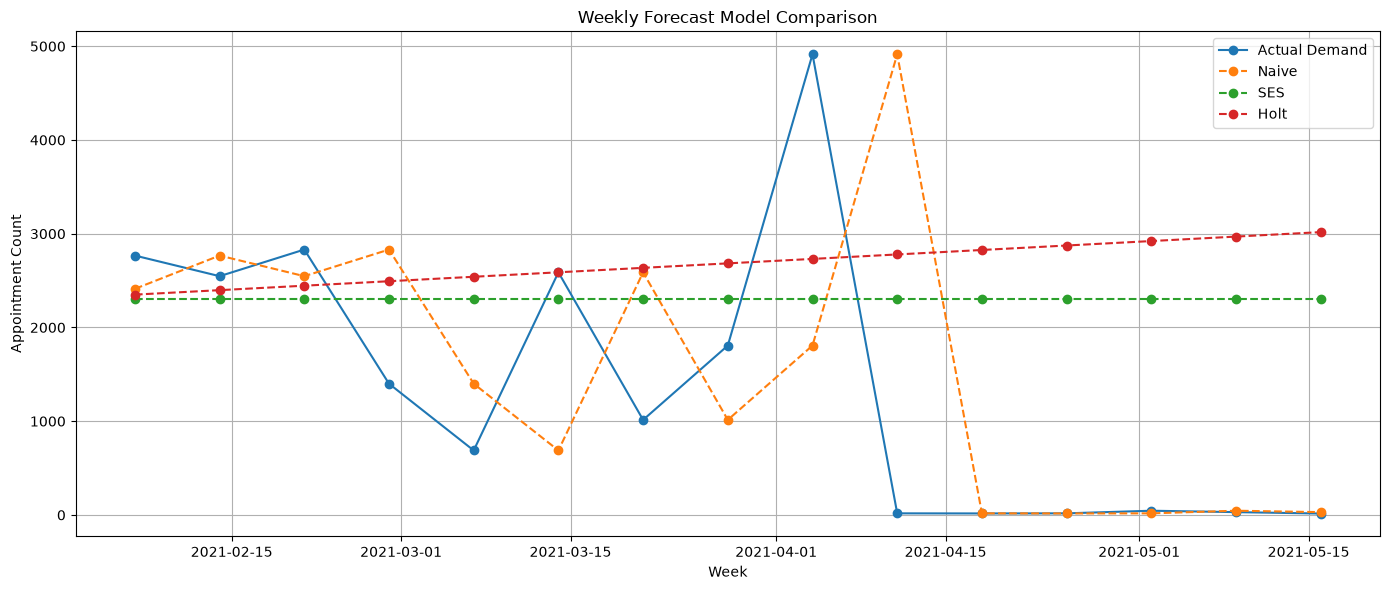

In [109]:
plt.figure(figsize=(14, 6))

plt.plot(
    weekly_test['week_ending'],
    weekly_test['appointment_count'],
    marker='o',
    label='Actual Demand'
)

plt.plot(
    weekly_test['week_ending'],
    weekly_test['naive_prediction'],
    linestyle='--',
    marker='o',
    label='Naive'
)

plt.plot(
    weekly_test['week_ending'],
    weekly_test['ses_prediction'],
    linestyle='--',
    marker='o',
    label='SES'
)

plt.plot(
    weekly_test['week_ending'],
    weekly_test['holt_prediction'],
    linestyle='--',
    marker='o',
    label='Holt'
)

plt.title('Weekly Forecast Model Comparison')
plt.xlabel('Week')
plt.ylabel('Appointment Count')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [110]:
hw_model = ExponentialSmoothing(
    weekly_train['appointment_count'],
    trend='add',
    seasonal='add',
    seasonal_periods=52,
    initialization_method='estimated'
).fit()

weekly_test['hw_prediction'] = hw_model.forecast(
    len(weekly_test)
)

print(
    weekly_test[
        ['week_ending', 'appointment_count', 'hw_prediction']
    ].round(2)
)

ValueError: Cannot compute initial seasonals using heuristic method with less than two full seasonal cycles in the data.

In [111]:
hw_model = ExponentialSmoothing(
    weekly_train['appointment_count'],
    trend='add',
    seasonal='add',
    seasonal_periods=4,
    initialization_method='estimated'
).fit()

weekly_test['hw_prediction'] = hw_model.forecast(
    len(weekly_test)
)

print(
    weekly_test[
        ['week_ending', 'appointment_count', 'hw_prediction']
    ].round(2)
)

   week_ending  appointment_count  hw_prediction
57  2021-02-07               2767        2926.05
58  2021-02-14               2547        3025.88
59  2021-02-21               2831        2641.07
60  2021-02-28               1400        2570.22
61  2021-03-07                688        3084.27
62  2021-03-14               2588        3184.10
63  2021-03-21               1014        2799.29
64  2021-03-28               1807        2728.44
65  2021-04-04               4914        3242.49
66  2021-04-11                 17        3342.32
67  2021-04-18                 16        2957.51
68  2021-04-25                 17        2886.66
69  2021-05-02                 45        3400.71
70  2021-05-09                 30        3500.54
71  2021-05-16                 15        3115.73


C:\Users\sadhu\AppData\Local\Temp\ipykernel_17316\3136514053.py:16: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


In [112]:
hw_mae = mean_absolute_error(
    weekly_test['appointment_count'],
    weekly_test['hw_prediction']
)

hw_rmse = np.sqrt(
    mean_squared_error(
        weekly_test['appointment_count'],
        weekly_test['hw_prediction']
    )
)

hw_r2 = r2_score(
    weekly_test['appointment_count'],
    weekly_test['hw_prediction']
)

print("Weekly Holt-Winters Model")
print("MAE:", round(hw_mae, 2))
print("RMSE:", round(hw_rmse, 2))
print("R2 Score:", round(hw_r2, 4))

Weekly Holt-Winters Model
MAE: 1895.48
RMSE: 2242.81
R2 Score: -1.42


In [113]:
weekly_model_comparison = pd.DataFrame({
    'Model': ['Naive', 'SES', 'Holt', 'Holt-Winters'],
    'MAE': [weekly_mae, ses_mae, holt_mae, hw_mae],
    'RMSE': [weekly_rmse, ses_rmse, holt_rmse, hw_rmse],
    'R2': [weekly_r2, ses_r2, holt_r2, hw_r2]
})

print(
    weekly_model_comparison
    .sort_values('MAE')
    .round(4)
    .to_string(index=False)
)

       Model       MAE      RMSE      R2
       Naive 1022.2000 1696.2980 -0.3843
         SES 1473.0166 1710.1109 -0.4069
        Holt 1721.7792 2045.3844 -1.0127
Holt-Winters 1895.4775 2242.8100 -1.4200


In [114]:
walk_forward_predictions = []

for i in range(len(weekly_test)):

    previous_actual = weekly_demand.iloc[
        split_index + i - 1
    ]['appointment_count']

    walk_forward_predictions.append(previous_actual)

weekly_test['walk_forward_naive'] = (
    walk_forward_predictions
)

print(
    weekly_test[
        ['week_ending', 'appointment_count',
         'walk_forward_naive']
    ]
)

   week_ending  appointment_count  walk_forward_naive
57  2021-02-07               2767                2412
58  2021-02-14               2547                2767
59  2021-02-21               2831                2547
60  2021-02-28               1400                2831
61  2021-03-07                688                1400
62  2021-03-14               2588                 688
63  2021-03-21               1014                2588
64  2021-03-28               1807                1014
65  2021-04-04               4914                1807
66  2021-04-11                 17                4914
67  2021-04-18                 16                  17
68  2021-04-25                 17                  16
69  2021-05-02                 45                  17
70  2021-05-09                 30                  45
71  2021-05-16                 15                  30


In [115]:
wf_mae = mean_absolute_error(
    weekly_test['appointment_count'],
    weekly_test['walk_forward_naive']
)

wf_rmse = np.sqrt(
    mean_squared_error(
        weekly_test['appointment_count'],
        weekly_test['walk_forward_naive']
    )
)

wf_r2 = r2_score(
    weekly_test['appointment_count'],
    weekly_test['walk_forward_naive']
)

print("Walk-Forward Naive Model")
print("MAE:", round(wf_mae, 2))
print("RMSE:", round(wf_rmse, 2))
print("R2 Score:", round(wf_r2, 4))

Walk-Forward Naive Model
MAE: 1022.2
RMSE: 1696.3
R2 Score: -0.3843


In [116]:
short_test = weekly_test.head(4).copy()

print(short_test[
    ['week_ending', 'appointment_count', 'naive_prediction']
])

   week_ending  appointment_count  naive_prediction
57  2021-02-07               2767            2412.0
58  2021-02-14               2547            2767.0
59  2021-02-21               2831            2547.0
60  2021-02-28               1400            2831.0


In [117]:
short_mae = mean_absolute_error(
    short_test['appointment_count'],
    short_test['naive_prediction']
)

short_rmse = np.sqrt(
    mean_squared_error(
        short_test['appointment_count'],
        short_test['naive_prediction']
    )
)

short_r2 = r2_score(
    short_test['appointment_count'],
    short_test['naive_prediction']
)

print("Four-Week Naive Forecast")
print("MAE:", round(short_mae, 2))
print("RMSE:", round(short_rmse, 2))
print("R2 Score:", round(short_r2, 4))

Four-Week Naive Forecast
MAE: 572.5
RMSE: 758.76
R2 Score: -0.7169


In [118]:
forecast_summary = pd.DataFrame({
    'Frequency': ['Daily', 'Weekly'],
    'Best_Model': ['SARIMA', 'Naive'],
    'MAE': [172.25, weekly_mae],
    'RMSE': [312.65, weekly_rmse],
    'MAPE': [82.95, np.nan],
    'R2': [-0.21, weekly_r2]
})

print(forecast_summary.round(2).to_string(index=False))

Frequency Best_Model     MAE    RMSE  MAPE    R2
    Daily     SARIMA  172.25  312.65 82.95 -0.21
   Weekly      Naive 1022.20 1696.30   NaN -0.38


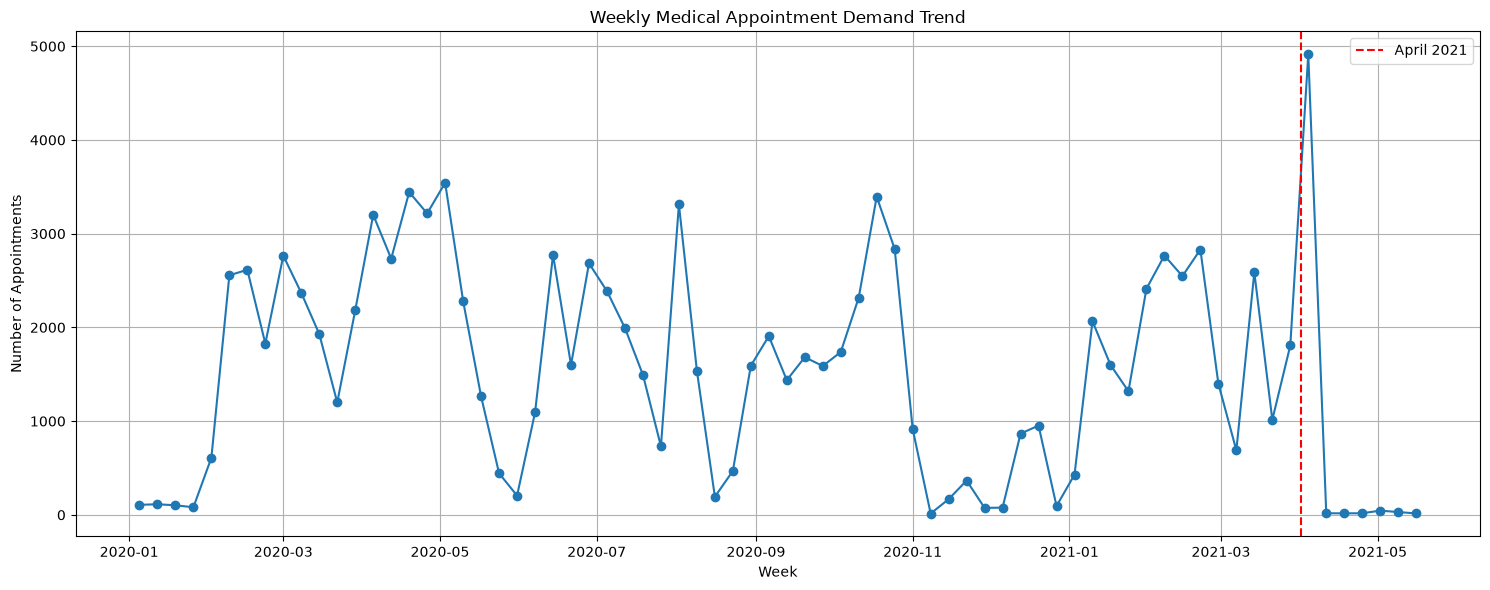

In [119]:
plt.figure(figsize=(15, 6))

plt.plot(
    weekly_demand['week_ending'],
    weekly_demand['appointment_count'],
    marker='o'
)

plt.axvline(
    pd.Timestamp('2021-04-01'),
    color='red',
    linestyle='--',
    label='April 2021'
)

plt.title('Weekly Medical Appointment Demand Trend')
plt.xlabel('Week')
plt.ylabel('Number of Appointments')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [120]:
print(
    weekly_demand['appointment_count'].describe().round(2)
)

count      72.00
mean     1522.12
std      1164.09
min        14.00
25%       413.25
50%      1563.00
75%      2445.75
max      4914.00
Name: appointment_count, dtype: float64


In [121]:
weekly_mean = weekly_demand['appointment_count'].mean()

weekly_std = weekly_demand['appointment_count'].std()

weekly_cv = (weekly_std / weekly_mean) * 100

print("Weekly Mean:", round(weekly_mean, 2))
print("Weekly Standard Deviation:", round(weekly_std, 2))
print("Coefficient of Variation:", round(weekly_cv, 2), "%")

Weekly Mean: 1522.12
Weekly Standard Deviation: 1164.09
Coefficient of Variation: 76.48 %


In [122]:
monthly_demand = (
    overall_demand
    .set_index('appointment_date_continuous')
    ['appointment_count']
    .resample('ME')
    .sum()
    .reset_index()
)

monthly_demand.columns = [
    'month',
    'appointment_count'
]

print(monthly_demand)

        month  appointment_count
0  2020-01-31                772
1  2020-02-29               9998
2  2020-03-31               8796
3  2020-04-30              13042
4  2020-05-31               6176
5  2020-06-30               8785
6  2020-07-31               9043
7  2020-08-31               4712
8  2020-09-30               6375
9  2020-10-31              10739
10 2020-11-30                649
11 2020-12-31               2241
12 2021-01-31               7569
13 2021-02-28               9545
14 2021-03-31               8665
15 2021-04-30               2423
16 2021-05-31                 63


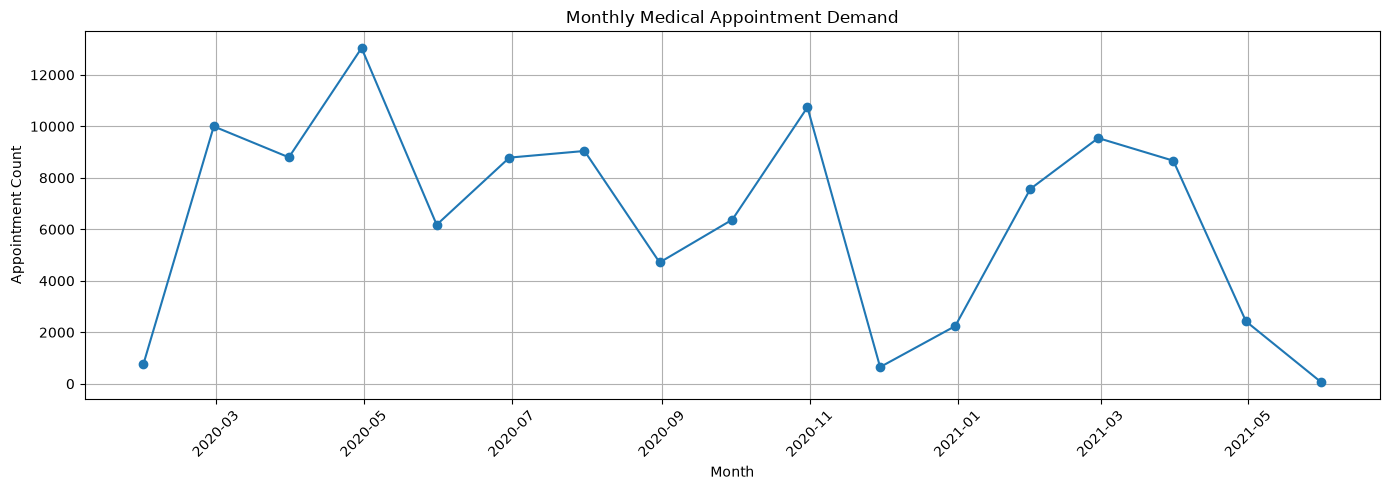

In [123]:
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_demand['month'],
    monthly_demand['appointment_count'],
    marker='o'
)

plt.title('Monthly Medical Appointment Demand')
plt.xlabel('Month')
plt.ylabel('Appointment Count')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [124]:
monthly_demand['days_recorded'] = (
    overall_demand
    .assign(
        month=overall_demand['appointment_date_continuous'].dt.to_period('M')
    )
    .groupby('month')
    .size()
    .values
)

monthly_demand['average_daily_demand'] = (
    monthly_demand['appointment_count'] /
    monthly_demand['days_recorded']
)

print(
    monthly_demand.round(2).to_string(index=False)
)

     month  appointment_count  days_recorded  average_daily_demand
2020-01-31                772             31                 24.90
2020-02-29               9998             29                344.76
2020-03-31               8796             31                283.74
2020-04-30              13042             30                434.73
2020-05-31               6176             31                199.23
2020-06-30               8785             30                292.83
2020-07-31               9043             31                291.71
2020-08-31               4712             31                152.00
2020-09-30               6375             30                212.50
2020-10-31              10739             31                346.42
2020-11-30                649             30                 21.63
2020-12-31               2241             31                 72.29
2021-01-31               7569             31                244.16
2021-02-28               9545             28                34

C:\Users\sadhu\AppData\Local\Temp\ipykernel_17316\4140327825.py:17: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  monthly_demand.round(2).to_string(index=False)


In [125]:
highest_month = monthly_demand.loc[
    monthly_demand['average_daily_demand'].idxmax()
]

lowest_month = monthly_demand.loc[
    monthly_demand['average_daily_demand'].idxmin()
]

print("Highest Demand Month:")
print(highest_month)

print("\nLowest Demand Month:")
print(lowest_month)

Highest Demand Month:
month                   2020-04-30 00:00:00
appointment_count                     13042
days_recorded                            30
average_daily_demand             434.733333
Name: 3, dtype: object

Lowest Demand Month:
month                   2021-05-31 00:00:00
appointment_count                        63
days_recorded                            12
average_daily_demand                   5.25
Name: 16, dtype: object


In [126]:
monthly_demand['monthly_change_pct'] = (
    monthly_demand['appointment_count']
    .pct_change() * 100
)

print(
    monthly_demand[
        ['month', 'appointment_count', 'monthly_change_pct']
    ].round(2).to_string(index=False)
)

     month  appointment_count  monthly_change_pct
2020-01-31                772                 NaN
2020-02-29               9998             1195.08
2020-03-31               8796              -12.02
2020-04-30              13042               48.27
2020-05-31               6176              -52.65
2020-06-30               8785               42.24
2020-07-31               9043                2.94
2020-08-31               4712              -47.89
2020-09-30               6375               35.29
2020-10-31              10739               68.45
2020-11-30                649              -93.96
2020-12-31               2241              245.30
2021-01-31               7569              237.75
2021-02-28               9545               26.11
2021-03-31               8665               -9.22
2021-04-30               2423              -72.04
2021-05-31                 63              -97.40


C:\Users\sadhu\AppData\Local\Temp\ipykernel_17316\1631387983.py:9: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2).to_string(index=False)


In [127]:
monthly_split = int(len(monthly_demand) * 0.8)

monthly_train = monthly_demand.iloc[:monthly_split].copy()
monthly_test = monthly_demand.iloc[monthly_split:].copy()

print("Training shape:", monthly_train.shape)
print("Testing shape:", monthly_test.shape)

print("\nTraining period:")
print(monthly_train['month'].min(), "to", monthly_train['month'].max())

print("\nTesting period:")
print(monthly_test['month'].min(), "to", monthly_test['month'].max())

Training shape: (13, 5)
Testing shape: (4, 5)

Training period:
2020-01-31 00:00:00 to 2021-01-31 00:00:00

Testing period:
2021-02-28 00:00:00 to 2021-05-31 00:00:00


In [128]:
monthly_naive_metrics = evaluate_model(
    monthly_test['appointment_count'],
    monthly_test['naive_prediction']
)

print("Monthly Naive Model Performance:")

for metric, value in monthly_naive_metrics.items():
    print(f"{metric}: {value:.2f}")

KeyError: 'naive_prediction'

In [129]:
monthly_test['naive_prediction'] = (
    monthly_demand['appointment_count']
    .shift(1)
    .loc[monthly_test.index]
)

print(
    monthly_test[
        ['month', 'appointment_count', 'naive_prediction']
    ]
)

        month  appointment_count  naive_prediction
13 2021-02-28               9545            7569.0
14 2021-03-31               8665            9545.0
15 2021-04-30               2423            8665.0
16 2021-05-31                 63            2423.0


In [130]:
monthly_naive_metrics = evaluate_model(
    monthly_test['appointment_count'],
    monthly_test['naive_prediction']
)

print("Monthly Naive Model Performance:")

for metric, value in monthly_naive_metrics.items():
    print(f"{metric}: {value:.2f}")

Monthly Naive Model Performance:
MAE: 2864.50
RMSE: 3507.53
MAPE: 1008.63
R2: 0.24


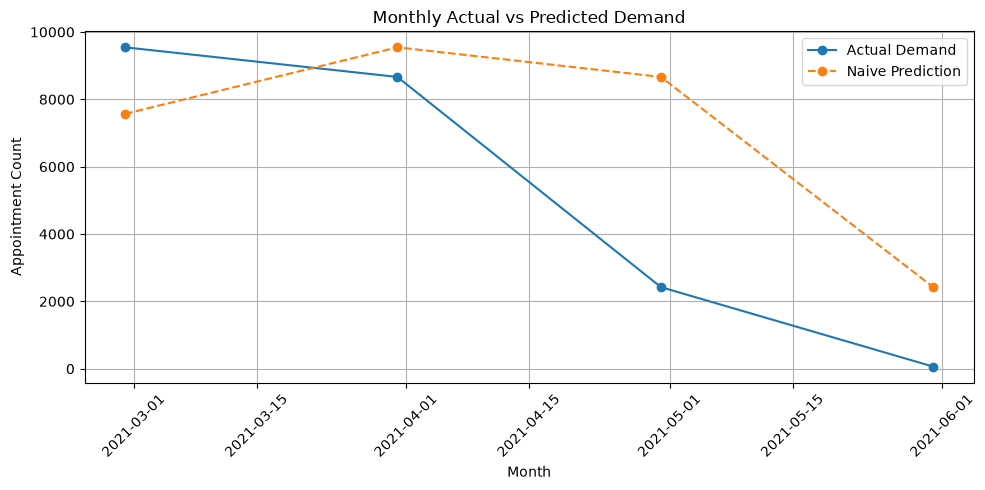

In [131]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_test['month'],
    monthly_test['appointment_count'],
    marker='o',
    label='Actual Demand'
)

plt.plot(
    monthly_test['month'],
    monthly_test['naive_prediction'],
    marker='o',
    linestyle='--',
    label='Naive Prediction'
)

plt.title('Monthly Actual vs Predicted Demand')
plt.xlabel('Month')
plt.ylabel('Appointment Count')
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [132]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

monthly_ses_model = SimpleExpSmoothing(
    monthly_train['appointment_count'],
    initialization_method='estimated'
).fit()

monthly_test['ses_prediction'] = (
    monthly_ses_model.forecast(len(monthly_test))
)

print(
    monthly_test[
        ['month', 'appointment_count', 'ses_prediction']
    ]
)

        month  appointment_count  ses_prediction
13 2021-02-28               9545     6838.258964
14 2021-03-31               8665     6838.258964
15 2021-04-30               2423     6838.258964
16 2021-05-31                 63     6838.258964


In [133]:
monthly_ses_metrics = evaluate_model(
    monthly_test['appointment_count'],
    monthly_test['ses_prediction']
)

print("Monthly SES Model Performance:")

for metric, value in monthly_ses_metrics.items():
    print(f"{metric}: {value:.2f}")

Monthly SES Model Performance:
MAE: 3931.00
RMSE: 4360.68
MAPE: 2746.51
R2: -0.17


In [134]:
monthly_model_comparison = pd.DataFrame({
    'Model': ['Naive', 'SES'],
    'MAE': [
        monthly_naive_metrics['MAE'],
        monthly_ses_metrics['MAE']
    ],
    'RMSE': [
        monthly_naive_metrics['RMSE'],
        monthly_ses_metrics['RMSE']
    ],
    'MAPE': [
        monthly_naive_metrics['MAPE'],
        monthly_ses_metrics['MAPE']
    ],
    'R2': [
        monthly_naive_metrics['R2'],
        monthly_ses_metrics['R2']
    ]
})

print(monthly_model_comparison.round(2))

   Model     MAE     RMSE     MAPE    R2
0  Naive  2864.5  3507.53  1008.63  0.24
1    SES  3931.0  4360.68  2746.51 -0.17


In [135]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

monthly_holt_model = ExponentialSmoothing(
    monthly_train['appointment_count'],
    trend='add',
    initialization_method='estimated'
).fit()

monthly_test['holt_prediction'] = (
    monthly_holt_model.forecast(len(monthly_test))
)

print(
    monthly_test[
        ['month', 'appointment_count', 'holt_prediction']
    ]
)

        month  appointment_count  holt_prediction
13 2021-02-28               9545      5254.401061
14 2021-03-31               8665      5028.127373
15 2021-04-30               2423      4801.853685
16 2021-05-31                 63      4575.579997


In [136]:
monthly_holt_metrics = evaluate_model(
    monthly_test['appointment_count'],
    monthly_test['holt_prediction']
)

print("Monthly Holt Model Performance:")

for metric, value in monthly_holt_metrics.items():
    print(f"{metric}: {value:.2f}")

Monthly Holt Model Performance:
MAE: 3704.73
RMSE: 3796.66
MAPE: 1836.98
R2: 0.11


In [137]:
monthly_model_comparison = pd.DataFrame({
    'Model': ['Naive', 'SES', 'Holt'],
    'MAE': [
        monthly_naive_metrics['MAE'],
        monthly_ses_metrics['MAE'],
        monthly_holt_metrics['MAE']
    ],
    'RMSE': [
        monthly_naive_metrics['RMSE'],
        monthly_ses_metrics['RMSE'],
        monthly_holt_metrics['RMSE']
    ],
    'MAPE': [
        monthly_naive_metrics['MAPE'],
        monthly_ses_metrics['MAPE'],
        monthly_holt_metrics['MAPE']
    ],
    'R2': [
        monthly_naive_metrics['R2'],
        monthly_ses_metrics['R2'],
        monthly_holt_metrics['R2']
    ]
})

print(monthly_model_comparison.round(2))

   Model      MAE     RMSE     MAPE    R2
0  Naive  2864.50  3507.53  1008.63  0.24
1    SES  3931.00  4360.68  2746.51 -0.17
2   Holt  3704.73  3796.66  1836.98  0.11


In [138]:
monthly_hw_model = ExponentialSmoothing(
    monthly_train['appointment_count'],
    trend='add',
    seasonal='add',
    seasonal_periods=3,
    initialization_method='estimated'
).fit()

monthly_test['hw_prediction'] = (
    monthly_hw_model.forecast(len(monthly_test))
)

print(
    monthly_test[
        ['month', 'appointment_count', 'hw_prediction']
    ]
)

        month  appointment_count  hw_prediction
13 2021-02-28               9545    3571.283973
14 2021-03-31               8665    4736.551583
15 2021-04-30               2423    6058.021416
16 2021-05-31                 63    2846.262615


In [139]:
monthly_hw_metrics = evaluate_model(
    monthly_test['appointment_count'],
    monthly_test['hw_prediction']
)

print("Monthly Holt-Winters Model Performance:")

for metric, value in monthly_hw_metrics.items():
    print(f"{metric}: {value:.2f}")

Monthly Holt-Winters Model Performance:
MAE: 4080.11
RMSE: 4244.94
MAPE: 1168.96
R2: -0.11


In [140]:
monthly_model_comparison = pd.DataFrame({
    'Model': ['Naive', 'SES', 'Holt', 'Holt-Winters'],
    'MAE': [
        monthly_naive_metrics['MAE'],
        monthly_ses_metrics['MAE'],
        monthly_holt_metrics['MAE'],
        monthly_hw_metrics['MAE']
    ],
    'RMSE': [
        monthly_naive_metrics['RMSE'],
        monthly_ses_metrics['RMSE'],
        monthly_holt_metrics['RMSE'],
        monthly_hw_metrics['RMSE']
    ],
    'MAPE': [
        monthly_naive_metrics['MAPE'],
        monthly_ses_metrics['MAPE'],
        monthly_holt_metrics['MAPE'],
        monthly_hw_metrics['MAPE']
    ],
    'R2': [
        monthly_naive_metrics['R2'],
        monthly_ses_metrics['R2'],
        monthly_holt_metrics['R2'],
        monthly_hw_metrics['R2']
    ]
})

print(monthly_model_comparison.round(2))

          Model      MAE     RMSE     MAPE    R2
0         Naive  2864.50  3507.53  1008.63  0.24
1           SES  3931.00  4360.68  2746.51 -0.17
2          Holt  3704.73  3796.66  1836.98  0.11
3  Holt-Winters  4080.11  4244.94  1168.96 -0.11


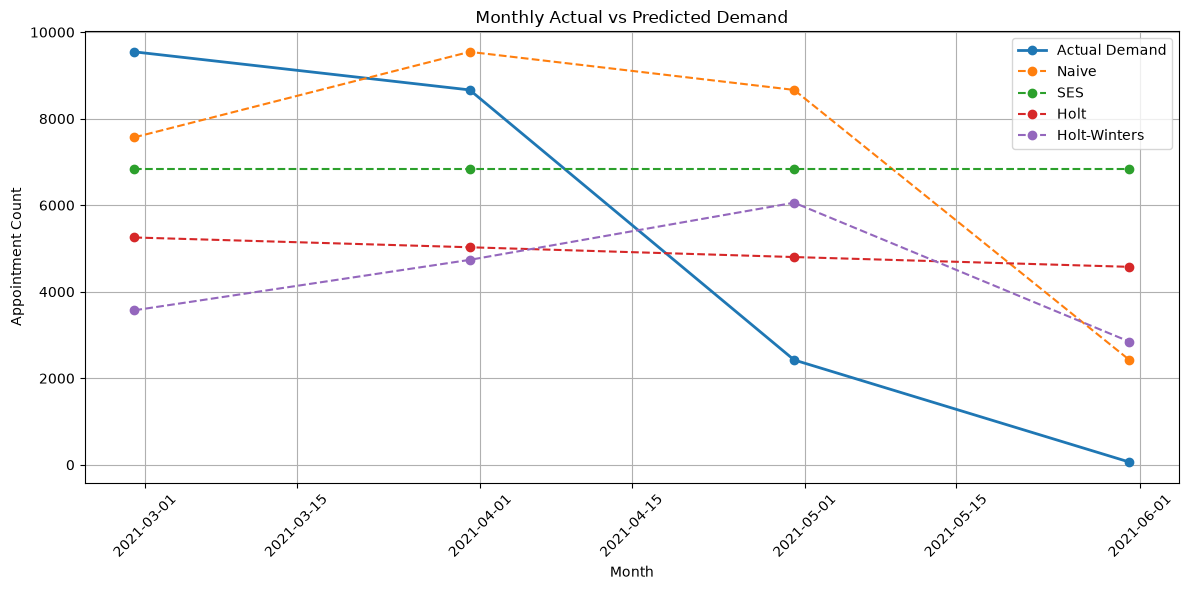

In [142]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_test['month'],
    monthly_test['appointment_count'],
    marker='o',
    linewidth=2,
    label='Actual Demand'
)

plt.plot(
    monthly_test['month'],
    monthly_test['naive_prediction'],
    marker='o',
    linestyle='--',
    label='Naive'
)

plt.plot(
    monthly_test['month'],
    monthly_test['ses_prediction'],
    marker='o',
    linestyle='--',
    label='SES'
)

plt.plot(
    monthly_test['month'],
    monthly_test['holt_prediction'],
    marker='o',
    linestyle='--',
    label='Holt'
)

plt.plot(
    monthly_test['month'],
    monthly_test['hw_prediction'],
    marker='o',
    linestyle='--',
    label='Holt-Winters'
)

plt.title('Monthly Actual vs Predicted Demand')
plt.xlabel('Month')
plt.ylabel('Appointment Count')
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [143]:
forecasting_summary = pd.DataFrame({
    'Frequency': ['Daily', 'Weekly', 'Monthly'],
    'Best_Model': ['SARIMA', 'Naive', 'Naive'],
    'MAE': [172.25, 1022.20, 2864.50],
    'RMSE': [312.65, 1696.30, 3507.53],
    'MAPE': [82.95, np.nan, 1008.63],
    'R2': [-0.21, -0.38, 0.24]
})

print(forecasting_summary)

  Frequency Best_Model      MAE     RMSE     MAPE    R2
0     Daily     SARIMA   172.25   312.65    82.95 -0.21
1    Weekly      Naive  1022.20  1696.30      NaN -0.38
2   Monthly      Naive  2864.50  3507.53  1008.63  0.24


In [144]:
forecasting_summary.to_csv(
    '../data/forecasting_model_comparison.csv',
    index=False
)

print("Forecasting summary saved successfully!")

Forecasting summary saved successfully!


In [145]:
final_demand_data = overall_demand.copy()

final_demand_data = final_demand_data.sort_values(
    'appointment_date_continuous'
).reset_index(drop=True)

print(final_demand_data.head())
print("\nShape:", final_demand_data.shape)
print("\nMissing values:")
print(final_demand_data.isnull().sum())

  appointment_date_continuous  appointment_count  rolling_7day_avg  \
0                  2020-01-01                 25               NaN   
1                  2020-01-02                 33               NaN   
2                  2020-01-03                 18               NaN   
3                  2020-01-04                 16               NaN   
4                  2020-01-05                 15               NaN   

           period  
0  Before April 2  
1  Before April 2  
2  Before April 2  
3  Before April 2  
4  Before April 2  

Shape: (498, 4)

Missing values:
appointment_date_continuous    0
appointment_count              0
rolling_7day_avg               6
period                         0
dtype: int64


In [146]:
print(final_demand_data['period'].value_counts())

print("\nLast 10 records:")
print(final_demand_data.tail(10))

period
Before April 2    457
From April 2       41
Name: count, dtype: int64

Last 10 records:
    appointment_date_continuous  appointment_count  rolling_7day_avg  \
488                  2021-05-03                  4          6.428571   
489                  2021-05-04                  3          5.428571   
490                  2021-05-05                  2          4.714286   
491                  2021-05-06                  5          5.285714   
492                  2021-05-07                 11          6.142857   
493                  2021-05-08                  1          5.000000   
494                  2021-05-09                  4          4.285714   
495                  2021-05-10                  3          4.142857   
496                  2021-05-11                 11          5.285714   
497                  2021-05-12                  1          5.142857   

           period  
488  From April 2  
489  From April 2  
490  From April 2  
491  From April 2  
492  From Ap

In [147]:
final_demand_data['period'] = np.where(
    final_demand_data['appointment_date_continuous']
    < '2021-04-03',
    'Before April 3',
    'From April 3'
)

print(final_demand_data['period'].value_counts())

period
Before April 3    458
From April 3       40
Name: count, dtype: int64


In [148]:
final_demand_data.to_csv(
    '../data/final_daily_demand.csv',
    index=False
)

print("Final daily demand dataset saved successfully!")

Final daily demand dataset saved successfully!
